# Task 07 — Public-procurement red flags: which tenders to audit first, without a fraud label

**Study unit:** ARI3217 — AI Enterprise Architectures and Transformation (University of Malta)
**Dataset:** [ProZorro. Ukrainian public procurement dataset](https://www.kaggle.com/datasets/oleksastepaniuk/prozorro-public-procurement-dataset) (competitive lots with every bidder, and every awarded lot, 2015–2019)
**Task family:** unsupervised risk scoring, graph analytics, multilingual text without an LLM · **Companion task:** `01_aml_graph_triage.ipynb` (the graph counterpart)

---

## The task card

> **Board question.** *Our audit office can open 200 tender reviews a month, out of about 22,600 competitive awards. Which 200 should it open first for signs of collusion or rigged competition, and how do we show, with no fraud label, that the list beats reviewing the biggest contracts?*

**Business context.** An audit office monitors an e-procurement platform after each award (Session 01's *batch prediction* pattern) and hands auditors a monthly queue (*human-in-the-loop*). The legacy estate is the platform's public API, the business register and the office's case-management tool; the model is a ranking layer between them. Findings arrive months later, and the flagged read the same public data and adapt. A flag is a lead, never an accusation.

**What you will build from this notebook (see *Student tasks* at the end):**

1. the given **red-flag indicators** and weighted score, packaged and reproducible, computed *as of* each tender, with the traps guarded by tests;
2. a **bidder co-participation graph** and an honest **ablation** of what it adds;
3. an **operating point** for 200 reviews a month (an ADR) and a **validation plan** without a label;
4. the **operational wrapper**: package, container, CI gate, registry, model card, monitoring plan;
5. an **auditor brief** (Stretch) that translates the Ukrainian fields and cites the records.

**Where this sits in the unit**

| Block | What this task exercises |
|---|---|
| 1 · EA for AI | Monthly batch scoring beside a public platform; audit capacity; sole traders' personal data |
| 2 · MLOps | As-of features, a forward-in-time proxy, drift when the law changes procedures (S04), versioned indicators (S06) |
| 3 · Semantic layer | Co-bidding graph, CPV classification as an ontology, buyer types (S07–S09) |
| 4 · LLM/RAG | Auditor brief grounded in the lead, citing records inside the audit system (S10–S11) |

**Assessment.** A *worked baseline plus tasks*; marks follow `docs/task-rubric.md`. The model is given: you are marked on how you package, evaluate, deploy, monitor and govern it, not on improving it. The notebook contains **deliberate traps**, each flagged with ⚠ in the text; turning each into a test is part of the task.

**Honesty note.** The data is **real** and public by law (ProZorro, Ukraine's e-procurement system), so the governance is real too. There is **no fraud label**: nothing here shows that any tender was rigged.

---

## How this notebook is organised

The notebook has three parts. Parts A and B are given; Part C is your assignment. **The model is given:** you package, evaluate, deploy and monitor it; you do not design, tune or replace it.

| Part | Sections | What it contains | What you do with it |
|---|---|---|---|
| **A · Explore the data** | 1–2 | Dataset card, first look, the Ukrainian fields without an LLM | Read. Its quirks go into your model card and data contract. |
| **B · The given model** | 3–6 | As-of red flags and the weighted score, the co-bidding graph and its ablation, validation without labels and the queue, the traps | Read, then package the code unchanged and reproduce its numbers (C2). |
| **C · Productionise it** | 7–10 | The flags after deployment, the module spine, student tasks, hand-in checklist | Your work: package, test, gate, track, serve, monitor, govern. Section 7 shows the drift your monitoring must catch. |

**What you need from Parts A and B**

- **Code to package:** `get_raw` and `load_procurement` with `pseudonym`, `code_kind` and `normalise_name` (Section 1); `translit` and `buyer_type` (Section 2); `participation`, `make_pairs`, `asof_features` and `score` (Section 3); `cobid_graph`, `louvain`, `community_features`, `clubs`, `design`, `fit_eval` and `precision_at_k` (Section 4); `review_queue`, `k_anonymity`, `evidence` and `printable_lead` (Section 5); `psi` for monitoring (Section 7).
- **Parameters for `config/config.yaml`:** the CAPITALS in Section 0.
- **Numbers your pipeline must reproduce (C2):** as-of features for 967,237 lots; the 2017 graph with 23,341 bidders, 87,452 edges and 1,312 communities (modularity 0.84), 6 clubs; proxy split of 103,493 multi-bidder lots in January–June 2018 and 87,647 in July–December (24.0 % with no price drop); proxy AUPRC 0.626 per-tender and 0.631 with the graph, precision@1,200 0.955; 22,567 competitive lots a month in 2018 against 200 reviews.
- **Runtime:** about 2 minutes on a laptop (98 s on the build machine).

## 0 · Setup

*Before Part A · the parameters below move into `config/config.yaml`.*

In [1]:
%matplotlib inline
import os, re, json, time, hmac, hashlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.csv as pc
import pyarrow.parquet as pq
import networkx as nx
import lightgbm as lgb
import sklearn
from scipy.stats import spearmanr
from sklearn.metrics import average_precision_score, roc_auc_score
from matplotlib.ticker import FuncFormatter, NullFormatter

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140); pd.set_option("display.max_colwidth", 80)

# ---- parameters -------------------------------------------------------------
SEED = 3217
KAGGLE_HANDLE = "oleksastepaniuk/prozorro-public-procurement-dataset"
FILES = ["Competitive_procurements.csv", "Suppliers.csv"]
HISTORY_MONTHS = 12                         # look-back for every history-based flag, ending the month BEFORE the tender
GRAPH_START, GRAPH_END = pd.Timestamp("2017-01-01"), pd.Timestamp("2018-01-01")   # the reference co-bidding graph
TRAIN_START, TEST_START, TEST_END = pd.Timestamp("2018-01-01"), pd.Timestamp("2018-07-01"), pd.Timestamp("2019-01-01")
REVIEWS_PER_MONTH = 200                     # tender reviews the audit office can open a month (assumption — task C3)
# indicator thresholds: design choices from the literature's definitions, not facts (vary them in C2 and C3)
PRICE_CLOSE = 0.99                          # final price at or above 99 % of the expected value counts as "close to reserve"
THRESHOLDS = {"goods and services": 200_000, "works": 1_500_000}   # UAH, open-tender thresholds, Law 922-VIII Art. 2 (our reading)
BUNCH_BAND = 0.05                           # "just below a threshold" = within 5 % under it
PAIR_MIN_TENDERS, PAIR_MIN_JACCARD = 4, 0.5 # "always together": >= 4 shared tenders in the look-back, Jaccard >= 0.5
ROTATION_MIN_SHARE = 0.25                   # rotation: an "always together" pair in which each has won >= 25 % of the joint tenders
COVER_MIN_BIDS = 10                         # cover bidder: >= 10 bids in the look-back and no win
REPEAT_MIN_LOTS, REPEAT_MIN_SHARE = 4, 0.5  # repeat winner: >= 50 % of the buyer's lots in the CPV division (>= 4 lots)
MAX_BIDDERS_FOR_PAIRS = 12                  # lots with more bidders are not expanded into pairs (cost; under 0.1 % of lots)
EDGE_MIN_TENDERS = 2                        # graph edge = two bidders met in >= 2 distinct tenders in the graph year
N_JOBS = 1
K_MIN = 10                                  # anything printed must match >= K_MIN lots on its quasi-identifiers (Trap 6)
PSEUDONYM_KEY = os.environ.get("PROZORRO_PSEUDONYM_KEY", "ari3217-task07-teaching-key").encode()  # production: a vault secret

DATA_DIR = Path(os.environ.get("DATASETS_TASKS_DATA", Path.cwd().parent.parent / "data"))
RAW, PROCESSED = DATA_DIR / "raw" / "prozorro", DATA_DIR / "processed"
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
np.random.seed(SEED)
T_START = time.time()

def free_memory():
    """Hand freed memory back to the operating system (glibc only; a no-op elsewhere). Keeps the peak near 1.5 GB."""
    import gc, ctypes
    gc.collect(); pa.default_memory_pool().release_unused()
    try:
        ctypes.CDLL("libc.so.6").malloc_trim(0)
    except OSError:
        pass
print(f"pandas {pd.__version__} · networkx {nx.__version__} · lightgbm {lgb.__version__} · scikit-learn {sklearn.__version__} · numpy {np.__version__}")

pandas 3.1.0 · networkx 3.7 · lightgbm 4.7.0 · scikit-learn 1.9.1 · numpy 2.5.4


# Part A — Explore the data

*Sections 1–2: read them; the quirks they find go into your model card and data contract.*

## 1 · Dataset card

*Part A · Explore · read; package `load_procurement` with `pseudonym`, `code_kind` and `normalise_name`.*

| Field | Value |
|---|---|
| **Source** | Kaggle `oleksastepaniuk/prozorro-public-procurement-dataset`, extracted from ProZorro's professional BI module (Kaggle Open Data Research Grant, 2020) |
| **Licence** | CC0 (public domain) |
| **Provenance** | Real. ProZorro became mandatory for central buyers in April 2016 and for all buyers in August 2016 (Law of Ukraine No. 922-VIII); the file starts with the 2015 pilot |
| **Size** | 2.77 GB: 2,313,168 bids on 984,859 competitive lots in 914,899 tenders; 3,621,822 awarded lots of every procedure; 92,145 bidders; 37,466 buyers |
| **Files** | `Competitive_procurements.csv` (1,098 MB): one row per lot and participant, `supplier_dummy` marks the winner. `Suppliers.csv` (1,674 MB): one row per awarded lot, competitive or not |
| **Schema** | date; buyer name, code, region; `lot_id`; procedure; CPV at three levels (with English text); expected (reserve) and final value in UAH; participant name, code, region |
| **Label** | None. Section 4 uses a proxy (two or more bidders, final price ≥ 99 % of expected): a symptom, not a verdict |
| **Window used here** | All of it, as compact Parquet. With a 12-month look-back, lots are scored from 2016; graph year 2017; evaluation 2018 (train H1, test H2); 2019 is the stream |
| **PII** | Codes: 8 digits (EDRPOU) for companies, 10 (RNOKPP) for natural persons, mostly sole traders (ФОП). Persons' names are never stored; codes become keyed hashes (reproducible with the teaching key; production uses a vault); printed leads are minimised (Trap 6) |

**Known quirks you must handle (and should mention in your model card):**

1. ⚠ **No single bidder above the threshold.** None of the 316,458 above-threshold lots (UA and EU procedures) has fewer than two bidders: the law cancels an open tender with fewer than two offers (Article 31, our reading). The single-bidder flag can fire only below the threshold and in the defence procedure.
2. ⚠ **Expected values pile up under the thresholds** (UAH 200,000 for goods and services, UAH 1.5 m for works; Article 2, our reading; the higher utility-sector thresholds are not applied here).
3. ⚠ **A lot is not a tender, and a row is not a firm** (Traps 1 and 5).
4. **The card promised Ukrainian tender titles; there are none.** The Ukrainian text is names; CPV descriptions are English. With no deadlines or losing bids, the *short bidding window* flag and bid-distribution screens (Imhof et al., 2018) cannot be computed.
5. **Codes need cleaning**, and one name can hide several codes (Trap 1).
6. **The system grew under the 2016 law**: early quarters are a different population (Section 7).

In [2]:
def get_raw(filename: str) -> Path:
    local = RAW / filename
    if local.exists():
        return local
    import kagglehub
    return Path(kagglehub.dataset_download(KAGGLE_HANDLE, path=filename))

def pseudonym(code: str) -> int:
    """Keyed hash of a registration code: joins still work, the code (for a sole trader, a personal tax number) does not leave the loader."""
    return int.from_bytes(hmac.new(PSEUDONYM_KEY, code.encode(), hashlib.sha256).digest()[:8], "big", signed=True)

def code_kind(code: str) -> tuple:
    """(kind, cleaned code). EDRPOU = 8 digits (legal entities); RNOKPP = 10 digits (natural persons, incl. sole traders)."""
    c = re.sub(r"\s+", "", code or "")
    if re.fullmatch(r"\d{8}", c):  return "edrpou", c
    if re.fullmatch(r"\d{10}", c): return "person_tax_no", c
    if re.fullmatch(r"[А-ЯІЇЄҐ]{2}\d{6}", c): return "person_passport", c          # people who refused a tax number
    if re.fullmatch(r"\d{5,7}", c): return "edrpou_lost_zeros", c.zfill(8)          # a spreadsheet ate the leading zeros
    m = re.fullmatch(r"(\d{8})[-/*].*", c)
    if m:                           return "edrpou_suffix", m.group(1)               # branch or typing suffix
    return ("blank", c) if c in ("", "-") else ("other", c)                          # mostly foreign registrations

PERSON_NAME = re.compile(r"^\W*(ФОП|ФО-П|ФО П|СПД|ФІЗИЧНА\s+ОСОБА)", re.IGNORECASE)
LATIN_LOOKALIKE = str.maketrans("ABCEHIKMOPTXY", "АВСЕНІКМОРТХУ")
FORMS = [(re.compile(p), f) for p, f in [   # legal forms: long and short spellings, Ukrainian and Russian -> one canonical token
    (r"ТОВАРИСТВО\s+З\s+ОБМЕЖЕНОЮ\s+ВІДПОВІДАЛЬНІСТЮ|ОБЩЕСТВО\s+С\s+ОГРАНИЧЕННОЙ\s+ОТВЕТСТВЕННОСТЬЮ|\bТЗОВ\b|\bТОВ\b|\bООО\b", "ТОВ"),
    (r"ТОВАРИСТВО\s+З\s+ДОДАТКОВОЮ\s+ВІДПОВІДАЛЬНІСТЮ|\bТДВ\b", "ТДВ"),
    (r"ПРИВАТНЕ\s+АКЦІОНЕРНЕ\s+ТОВАРИСТВО|\bПРАТ\b", "ПРАТ"),
    (r"ПУБЛІЧНЕ\s+АКЦІОНЕРНЕ\s+ТОВАРИСТВО|\bПАТ\b", "ПАТ"),
    (r"АКЦІОНЕРНЕ\s+ТОВАРИСТВО|\bАТ\b", "АТ"),
    (r"ПРИВАТНЕ\s+ПІДПРИЄМСТВО|ЧАСТНОЕ\s+ПРЕДПРИЯТИЕ|\bПП\b|\bЧП\b", "ПП"),
    (r"ДЕРЖАВНЕ\s+ПІДПРИЄМСТВО|\bДП\b", "ДП"),
    (r"КОМУНАЛЬНЕ\s+ПІДПРИЄМСТВО|\bКП\b", "КП"),
    (r"(СЕЛЯНСЬКЕ\s+)?ФЕРМЕРСЬКЕ\s+ГОСПОДАРСТВО|\bСФГ\b|\bФГ\b", "ФГ"),
    (r"НАУКОВО[-\s]*ВИРОБНИЧЕ\s+ПІДПРИЄМСТВО|\bНВП\b", "НВП")]]

def normalise_name(name: str) -> tuple:
    """(legal form, core name): upper case, quotes and punctuation out, Latin look-alike letters folded to Cyrillic."""
    s = re.sub(r"[’ʼ`´‘]", "'", re.sub(r"[«»\"“”„‟″]", " ", (name or "").upper()))
    n_cyr, n_lat = len(re.findall(r"[А-ЯІЇЄҐ]", s)), len(re.findall(r"[A-Z]", s))
    mixed = n_cyr > 0 and n_lat > 0
    if n_cyr > n_lat:
        s = s.translate(LATIN_LOOKALIKE)
    form = ""
    for pat, f in FORMS:
        if pat.search(s):
            form = form or f
            s = pat.sub(" ", s)
    return form, re.sub(r"[^\w']+", " ", s).strip(), mixed

def stream_csv(fname, string_cols, float_cols):
    co = pc.ConvertOptions(include_columns=string_cols + float_cols, column_types={
        **{c: pa.string() for c in string_cols}, **{c: pa.float64() for c in float_cols}, "lot_announce_date": pa.date32()})
    yield from pc.open_csv(get_raw(fname), read_options=pc.ReadOptions(block_size=16 << 20), convert_options=co)

CACHE_STRINGS = {"lots": ["buyer", "buyer_region", "ptype", "cpv", "cpv4", "cpv2"],
                 "bids": ["code_kind", "form", "core", "bidder_region"],
                 "contracts": ["buyer", "buyer_region", "ptype", "cpv2"], "buyers": [], "cpv": []}

def read_cache(name):
    """Parquet -> pandas with the repeated strings as categoricals (keeps the whole window near 0.5 GB in memory)."""
    return pq.read_table(PROCESSED / f"07_{name}.parquet", read_dictionary=CACHE_STRINGS[name]).to_pandas(date_as_object=False)

def load_procurement():
    names = list(CACHE_STRINGS)
    meta_path = PROCESSED / "07_meta.json"
    if all((PROCESSED / f"07_{n}.parquet").exists() for n in names) and meta_path.exists():
        return [read_cache(n) for n in names] + [json.load(open(meta_path))]
    t = time.time()
    ident, cpv_names, buyer_names, writers = {}, {}, {}, {}
    ID_COLS = ["bidder", "bidder_raw", "code_kind", "is_person", "form", "core", "mixed_script", "person_by_name"]

    def write(name, table):   # stream every batch straight to Parquet: memory stays at one batch
        if name not in writers:
            writers[name] = pq.ParquetWriter(PROCESSED / f"07_{name}.parquet.tmp", table.schema)
        writers[name].write_table(table)

    def resolve(code, name):
        """One (code, name) -> pseudonymised keys and governance flags. Names of natural persons are never kept."""
        kind, clean = code_kind(code)
        person = kind.startswith("person") or bool(PERSON_NAME.match(name or ""))
        form, core, mixed = ("", "", False) if person else normalise_name(name)
        return (pseudonym(clean), pseudonym(code or ""), kind, person, form, core, mixed, person and not kind.startswith("person"))

    def split_cpv(s):
        s = s.fillna("")
        code = s.str.split("_", n=1).str[0]
        cpv_names.update(dict(zip(code, s.str.split("_", n=1).str[1])))
        return code

    # ---- pass 1 · competitive procurements: one row per (lot, participant) ----
    sc = ["lot_announce_date", "organizer_name", "organizer_code", "organizer_region", "lot_id", "lot_procur_type", "lot_cpv",
          "lot_cpv_4_digs", "lot_cpv_2_digs", "participant_name", "participant_code", "participant_region", "supplier_dummy"]
    for batch in stream_csv(FILES[0], sc, ["lot_initial_value", "lot_final_value"]):
        df = batch.to_pandas()
        for c in ["lot_cpv", "lot_cpv_4_digs", "lot_cpv_2_digs"]:
            df[c] = split_cpv(df[c])
        buyer_names.update(dict(zip(df.organizer_code, df.organizer_name)))
        key = df.participant_code.fillna("") + "\x1f" + df.participant_name.fillna("")
        for k in key.unique():
            if k not in ident:
                ident[k] = resolve(*k.split("\x1f", 1))
        b = pd.DataFrame([ident[k] for k in key], columns=ID_COLS).drop(columns=["mixed_script", "person_by_name"])
        b.insert(0, "lot_id", df.lot_id.values)
        b["bidder_region"], b["winner"] = df.participant_region.values, df.supplier_dummy.astype("int8").values
        write("bids", pa.Table.from_pandas(b, preserve_index=False))
        lt = df.drop_duplicates("lot_id")[["lot_id", "lot_announce_date", "organizer_code", "organizer_region", "lot_procur_type",
                                           "lot_cpv", "lot_cpv_4_digs", "lot_cpv_2_digs", "lot_initial_value", "lot_final_value"]]
        lt.columns = ["lot_id", "date", "buyer", "buyer_region", "ptype", "cpv", "cpv4", "cpv2", "value", "final_value"]
        write("lots", pa.Table.from_pandas(lt, preserve_index=False))
        del df, key, b   # participant names end here: only the keyed hash and, for legal entities, the normalised name survive
    v = pd.DataFrame(ident.values(), columns=ID_COLS)
    meta = {"competitive_identities": len(v), "code_kinds": v.code_kind.value_counts().to_dict(),
            "person_identities": int(v.is_person.sum()), "person_by_name_only": int(v.person_by_name.sum()),
            "mixed_script_names": int(v.mixed_script.sum())}
    del ident, v

    # ---- pass 2 · suppliers: one row per awarded lot, competitive or not; names never read, codes hashed ----
    kinds = {}
    sc = ["lot_announce_date", "organizer_name", "organizer_code", "organizer_region", "lot_procur_type",
          "lot_competitiveness", "lot_cpv_2_digs", "supplier_code"]
    for batch in stream_csv(FILES[1], sc, ["lot_initial_value", "lot_final_value"]):
        codes = batch.column("supplier_code").to_pandas()
        for c in codes.unique():
            if c not in kinds:
                k, clean = code_kind(c)
                kinds[c] = (pseudonym(clean), k.startswith("person"))
        org = batch.select(["organizer_code", "organizer_name"]).to_pandas().drop_duplicates("organizer_code")
        buyer_names.update(dict(zip(org.organizer_code, org.organizer_name)))
        write("contracts", pa.table({
            "date": batch.column("lot_announce_date"), "buyer": batch.column("organizer_code"),
            "buyer_region": batch.column("organizer_region"), "ptype": batch.column("lot_procur_type"),
            "competitive": pa.array(batch.column("lot_competitiveness").to_pandas().astype("int8")),
            "cpv2": pa.array(split_cpv(batch.column("lot_cpv_2_digs").to_pandas())),
            "value": batch.column("lot_initial_value"), "final_value": batch.column("lot_final_value"),
            "supplier": pa.array(codes.map(lambda c: kinds[c][0]).astype("int64")),
            "supplier_is_person": pa.array(codes.map(lambda c: kinds[c][1]).astype(bool))}))
    del kinds
    for w in writers.values():
        w.close()

    # ---- pass 3 · tidy: one row per lot, bids keyed by lot number, everything sorted by date ----
    lots = pq.read_table(PROCESSED / "07_lots.parquet.tmp", read_dictionary=["buyer", "buyer_region", "ptype", "cpv", "cpv4", "cpv2"]).to_pandas()
    lots = lots.drop_duplicates("lot_id").assign(date=lambda d: pd.to_datetime(d.date))
    lots["tender_id"] = lots.lot_id.str.replace(r"-L\d+$", "", regex=True)
    lots = lots.sort_values(["date", "lot_id"], ignore_index=True)
    bids = pq.read_table(PROCESSED / "07_bids.parquet.tmp", read_dictionary=["lot_id", "code_kind", "form", "core", "bidder_region"]).to_pandas()
    lot_no = pd.Series(np.arange(len(lots), dtype="int32"), index=lots.lot_id)
    bids.insert(0, "lot", lot_no.reindex(bids.lot_id.cat.categories).to_numpy()[bids.lot_id.cat.codes])
    bids = bids.drop(columns="lot_id").sort_values(["lot", "winner"], ascending=[True, False], ignore_index=True)
    meta["competitive_rows"] = len(bids)
    lots.to_parquet(PROCESSED / "07_lots.parquet"); bids.to_parquet(PROCESSED / "07_bids.parquet")
    del lots, bids
    (PROCESSED / "07_contracts.parquet.tmp").replace(PROCESSED / "07_contracts.parquet")
    for n in ["lots", "bids"]:
        (PROCESSED / f"07_{n}.parquet.tmp").unlink()
    pd.DataFrame({"buyer": list(buyer_names), "buyer_name": list(buyer_names.values())}).to_parquet(PROCESSED / "07_buyers.parquet")
    pd.DataFrame({"code": list(cpv_names), "description": list(cpv_names.values())}).to_parquet(PROCESSED / "07_cpv.parquet")
    json.dump(meta, open(meta_path, "w"), indent=1)
    print(f"loaded + cached in {time.time()-t:.0f}s")
    return [read_cache(n) for n in names] + [meta]

lots, bids, contracts, buyers, cpv_tbl, META = load_procurement()
CPV = dict(zip(cpv_tbl.code, cpv_tbl.description))
month_index = lambda ts: (ts.year - 2015) * 12 + ts.month - 1          # Jan 2015 = 0
print(f"{len(lots):,} competitive lots in {lots.tender_id.nunique():,} tenders · {len(bids):,} bids by {bids.bidder.nunique():,} bidders "
      f"({bids.loc[bids.is_person, 'bidder'].nunique():,} natural persons, names dropped) · {len(contracts):,} awarded lots in Suppliers.csv · "
      f"{lots.date.min():%b %Y}–{lots.date.max():%b %Y} · {(lots.memory_usage(deep=True).sum() + bids.memory_usage(deep=True).sum() + contracts.memory_usage(deep=True).sum())/1e6:.0f} MB")

# ---- Suppliers.csv serves two purposes here: the method mix over time, and each buyer's use of non-open procedures ----
NON_OPEN = ["Negotiation", "Quick Negotiation"]
mix_q = (contracts.groupby([contracts.date.dt.to_period("Q"), "ptype"], observed=True)
                  .agg(lots=("buyer", "size"), value=("value", "sum")).reset_index().rename(columns={"date": "quarter"}))
contracts["m"] = month_index(contracts.date.dt).astype("int16")
contracts["buyer_no"] = contracts.buyer.astype(str).map(pd.Series(np.arange(len(lots.buyer.cat.categories)), index=lots.buyer.cat.categories)).fillna(-1).astype("int32")
buyer_contracts = (contracts.assign(non_open=contracts.ptype.isin(NON_OPEN)).groupby(["buyer_no", "m"])
                            .agg(c_all=("non_open", "size"), c_non_open=("non_open", "sum")).reset_index())
N_CONTRACTS = len(contracts)
del contracts                                                           # 3.6 M rows we no longer need
bids = bids.drop(columns="bidder_region"); lots = lots.drop(columns="cpv4")
free_memory()

984,859 competitive lots in 914,899 tenders · 2,313,168 bids by 92,145 bidders (34,073 natural persons, names dropped) · 3,621,822 awarded lots in Suppliers.csv · Feb 2015–Dec 2019 · 318 MB


## 2 · First look: procedures, thresholds and the Ukrainian fields

*Part A · Explore · read; package `translit` and `buyer_type`, the lexicon the indicators and S1 reuse.*

What decides everything that follows: the procedure (set by the law's thresholds), how many firms bid, and how far the price fell.

In [3]:
# ---- one row per lot: bidders, winner, price ratio ----
N_LOTS = len(lots)
lots["n_rows"] = bids.groupby("lot").size().reindex(np.arange(N_LOTS), fill_value=0).to_numpy().astype("int16")
lots["n_bidders"] = bids.groupby("lot").bidder.nunique().reindex(np.arange(N_LOTS), fill_value=0).to_numpy().astype("int16")  # distinct firms
lots["winner"] = bids[bids.winner == 1].drop_duplicates("lot").set_index("lot").bidder.reindex(np.arange(N_LOTS)).to_numpy()
lots["ratio"] = lots.final_value / lots.value                       # final price ÷ expected value (the reserve)
lots["works"] = lots.cpv2.astype(str).eq("45000000-7")              # CPV division 45 = construction works
lots["threshold"] = np.where(lots.works, THRESHOLDS["works"], THRESHOLDS["goods and services"]).astype("int32")
PTYPES = ["Below Threshold", "Above Threshold UA", "Above Threshold EU", "Above Threshold UA Defense"]
proc = (lots.groupby("ptype", observed=True)
            .agg(lots=("lot_id", "size"), median_value_uah=("value", "median"), mean_bidders=("n_bidders", "mean"),
                 single_bidder=("n_bidders", lambda s: (s == 1).mean()), median_final_vs_expected=("ratio", "median"))
            .reindex(PTYPES))
display(proc.style.format({"lots": "{:,}", "median_value_uah": "{:,.0f}", "mean_bidders": "{:.2f}", "single_bidder": "{:.1%}",
                           "median_final_vs_expected": "{:.3f}"}))
print("Suppliers.csv, all awarded lots by procedure (competitive and not):")
mix = mix_q.groupby("ptype", observed=True).agg(lots=("lots", "sum"), value_bn_uah=("value", "sum"))
mix["value_bn_uah"] /= 1e9
display(mix.sort_values("lots", ascending=False).style.format({"lots": "{:,}", "value_bn_uah": "{:,.0f}"}))

,lots,median_value_uah,mean_bidders,single_bidder,median_final_vs_expected
ptype,,,,,
Below Threshold,"661,889","27,535",2.17,44.7%,0.918
Above Threshold UA,"292,074","419,141",2.71,0.0%,0.956
Above Threshold EU,"24,384","5,214,686",2.83,0.0%,0.983
Above Threshold UA Defense,"6,512","1,304,716",2.33,39.5%,0.986


Suppliers.csv, all awarded lots by procedure (competitive and not):


,lots,value_bn_uah
ptype,,
Reporting,"2,447,400",335
Below Threshold,"661,889",179
Above Threshold UA,"292,074",431
Negotiation,"100,841",201
Quick Negotiation,"88,722",152
Above Threshold EU,"24,384",592
Above Threshold UA Defense,"6,512",52


goods/services, below-threshold procedure: 15,982 lots at UAH 190–200k against 4,783 at 180–190k and 979 at 200–210k · works: 1,250 at 1.4–1.5m against 682 at 1.3–1.4m


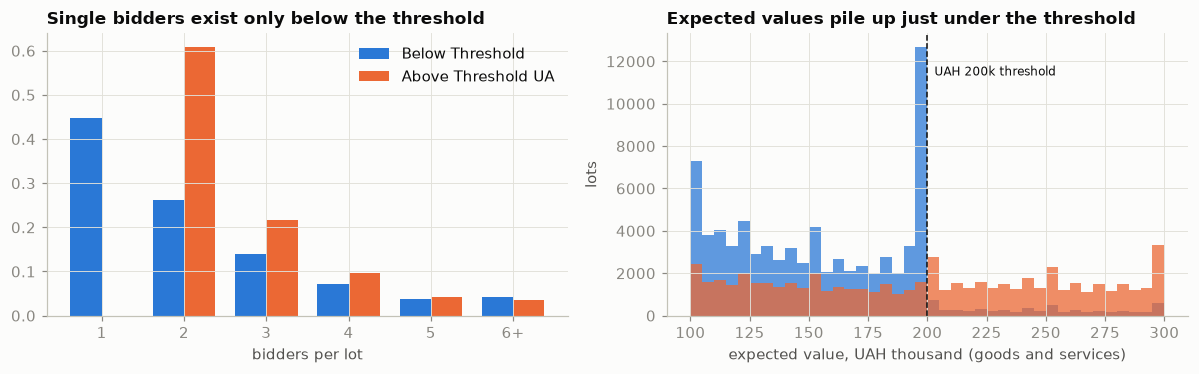

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
ax = axes[0]
nb = lots.assign(nb=lots.n_bidders.clip(upper=6)).groupby(["ptype", "nb"], observed=True).size().unstack(0).reindex(columns=PTYPES[:2])
nb = nb / nb.sum()
for i, (c, color) in enumerate(zip(nb.columns, SERIES)):
    ax.bar(nb.index + (i - 0.5) * 0.38, nb[c], width=0.38, color=color, label=c)
ax.set_xticks(range(1, 7), ["1", "2", "3", "4", "5", "6+"]); ax.set_xlabel("bidders per lot"); ax.legend()
ax.set_title("Single bidders exist only below the threshold")
ax = axes[1]
gs = lots[~lots.works & lots.value.between(100_000, 300_000)]
edges = np.arange(100_000, 300_001, 5_000)
for c, color in zip(PTYPES[:2], SERIES):
    ax.hist(gs.loc[gs.ptype == c, "value"] / 1e3, bins=edges / 1e3, color=color, alpha=0.75, label=c)
ax.axvline(200, color=INK, lw=1, ls="--"); ax.text(203, ax.get_ylim()[1] * 0.85, "UAH 200k threshold", fontsize=8, color=INK)
ax.set_xlabel("expected value, UAH thousand (goods and services)"); ax.set_ylabel("lots")
ax.set_title("Expected values pile up just under the threshold")
plt.tight_layout()
bin_ = lambda lo, hi, m: int((m & lots.value.ge(lo) & lots.value.lt(hi)).sum())
below = lots.ptype.eq("Below Threshold")
print(f"goods/services, below-threshold procedure: {bin_(190e3, 200e3, below & ~lots.works):,} lots at UAH 190–200k "
      f"against {bin_(180e3, 190e3, below & ~lots.works):,} at 180–190k and {bin_(200e3, 210e3, below & ~lots.works):,} at 200–210k · "
      f"works: {bin_(1.4e6, 1.5e6, below & lots.works):,} at 1.4–1.5m against {bin_(1.3e6, 1.4e6, below & lots.works):,} at 1.3–1.4m")

**Reading this.** Below the threshold 44.7 % of lots have one bidder and the median lot ends at 92 % of its expected value; above it, single bidders are absent by law and the median ends at 96 %. On the right, the threshold at work: 15,982 below-threshold goods-and-services lots sit at UAH 190–200k, against 4,783 at 180–190k and 979 at 200–210k; works step the same way under UAH 1.5 m. Bunching under a discretionary threshold is a known manipulation signal (Palguta & Pertold, 2017).

### The Ukrainian fields, without an LLM

The text here is names, almost all Ukrainian. **Transliteration** under the national standard (Cabinet of Ministers resolution No. 55 of 2010) makes a name readable for an auditor without Cyrillic, but does not translate it. A **stem lexicon** of 14 rules turns a buyer's name into a type (`ЛІКАРН` → health care).

In [5]:
# ---- Ukrainian fields without an LLM: a transliteration standard and a stem lexicon ----
UA_LAT = dict(zip("абвгґдеєжзиіїйклмнопрстуфхцчшщьюя", ["a", "b", "v", "h", "g", "d", "e", "ie", "zh", "z", "y", "i", "i", "i", "k", "l",
                  "m", "n", "o", "p", "r", "s", "t", "u", "f", "kh", "ts", "ch", "sh", "shch", "", "iu", "ia"]))
UA_LAT_INITIAL = {"є": "ye", "ї": "yi", "й": "y", "ю": "yu", "я": "ya"}

def translit(text: str) -> str:
    """Ukrainian national transliteration (Cabinet of Ministers resolution No. 55 of 2010): readable, not a translation."""
    def word(w):
        lw = w.lower().replace("зг", "зґх")                     # 'зг' -> 'zgh' (marked with ґх, mapped below)
        out = "".join((UA_LAT_INITIAL.get(ch) if i == 0 and ch in UA_LAT_INITIAL else UA_LAT.get(ch, ch if ch not in "'’ʼ" else ""))
                      for i, ch in enumerate(lw)).replace("gkh", "gh")
        return out.upper() if w.isupper() and len(w) > 1 else (out[:1].upper() + out[1:] if w[:1].isupper() else out)
    return re.sub(r"[\w'’ʼ]+", lambda m: word(m.group()), text or "")

BUYER_TYPES = [  # (stems in the upper-cased Ukrainian name, English type); first match wins, so the order matters
    (r"ВІЙСЬКОВА ЧАСТИНА|\bВ/Ч\b", "military unit"),
    (r"ЛІКАРН|ПОЛІКЛІНІК|МЕДИЧН|МЕДИКО|ПОЛОГОВ|ДИСПАНСЕР|САНАТОР|АМБУЛАТОР|ЗДОРОВ", "health care"),
    (r"ДОШКІЛЬН|ДИТЯЧИЙ САДОК|ЯСЛА|\bДНЗ\b|\bЗДО\b", "kindergarten"),
    (r"ШКОЛ|ГІМНАЗІ|ЛІЦЕ|ЗАГАЛЬНООСВІТН|НАВЧАЛЬНО-ВИХОВН|\bЗОШ\b|\bНВК\b", "school"),
    (r"УНІВЕРСИТЕТ|ІНСТИТУТ|АКАДЕМІ|КОЛЕДЖ|ТЕХНІКУМ|УЧИЛИЩ", "university or college"),
    (r"ОСВІТ", "education authority"),
    (r"\bРАДА\b|\bРАДИ\b", "council"),
    (r"АДМІНІСТРАЦІ", "state administration"),
    (r"ПОЛІЦІ|ПРОКУРАТУР|\bСУД|ПЕНІТЕНЦІАР|ВИКОНАННЯ ПОКАРАНЬ|ПРИКОРДОНН|ГВАРДІ|НАДЗВИЧАЙНИХ СИТУАЦІЙ", "justice and security"),
    (r"ВОДОКАНАЛ|ТЕПЛО|ЕНЕРГ|ЕЛЕКТР|ГАЗ|ЗАЛІЗНИЦ|АВТОМОБІЛЬНИХ ДОРІГ|АВТОДОР", "utility, energy or transport"),
    (r"КУЛЬТУР|БІБЛІОТЕК|МУЗЕ|ТЕАТР|ФІЛАРМОНІ|СПОРТ", "culture and sport"),
    (r"СОЦІАЛЬН|ПЕНСІЙН|ЗАЙНЯТОСТІ|ІНТЕРНАТ", "social services"),
    (r"УПРАВЛІННЯ|ДЕПАРТАМЕНТ|МІНІСТЕРСТВ|АГЕНТСТВ|СЛУЖБ|ІНСПЕКЦІ|КОМІТЕТ|ФОНД|ВІДДІЛ", "government agency"),
    (r"ПІДПРИЄМСТВО|ТОВАРИСТВО|\bКП\b|\bДП\b|\bАТ\b|\bПАТ\b|\bПРАТ\b", "public enterprise"),
]
BUYER_TYPES = [(re.compile(p), t) for p, t in BUYER_TYPES]
def buyer_type(name: str) -> str:
    u = (name or "").upper()
    return next((t for p, t in BUYER_TYPES if p.search(u)), "other")

buyers["type"] = buyers.buyer_name.map(buyer_type)
buyers["russian_letters"] = buyers.buyer_name.str.contains(r"[ыэёъЫЭЁЪ]")          # letters Ukrainian does not use
btype = pd.Series(buyers.type.to_numpy(), index=buyers.buyer)
lots["buyer_type"] = lots.buyer.astype(str).map(btype).fillna("other").astype("category")
cov = pd.DataFrame({"buyers": buyers.type.value_counts(normalize=True), "lots": lots.buyer_type.value_counts(normalize=True)})
share33 = lambda m: lots.loc[m, "cpv2"].astype(str).eq("33000000-0").mean()
share15 = lambda m: lots.loc[m, "cpv2"].astype(str).eq("15000000-8").mean()
hc, kids = lots.buyer_type.eq("health care"), lots.buyer_type.isin(["kindergarten", "school"])
print(f"lexicon of {len(BUYER_TYPES)} rules types {1 - cov.loc['other', 'buyers']:.0%} of {len(buyers):,} buyers and "
      f"{1 - cov.loc['other', 'lots']:.0%} of lots · sanity: medical goods (CPV 33) are {share33(hc):.0%} of health-care buyers' lots "
      f"against {share33(~hc):.0%} elsewhere; food (CPV 15) is {share15(kids):.0%} of schools' and kindergartens' lots against {share15(~kids):.0%}")
untyped = buyers.loc[buyers.type == "other", "buyer_name"].str.upper().str.findall(r"[А-ЯІЇЄҐ']{4,}").explode().value_counts()
print(f"buyer names with Russian-only letters: {buyers.russian_letters.sum():,} · most common words in untyped names: "
      + ", ".join(f"{w} ({translit(w)}, {n:,})" for w, n in untyped.head(6).items()))
big = lots.groupby("buyer", observed=True).size().sort_values(ascending=False)
ex = buyers.set_index("buyer").loc[big.index[:400]].groupby("type").head(1).head(6)
display(pd.DataFrame({"name (public body)": ex.buyer_name.str.slice(0, 58), "transliteration": ex.buyer_name.map(translit).str.slice(0, 58),
                      "lexicon type": ex.type}).reset_index(drop=True))
display(cov.sort_values("lots", ascending=False).head(8).style.format("{:.1%}").set_caption("Buyer types from the lexicon"))

lexicon of 14 rules types 84% of 37,466 buyers and 92% of lots · sanity: medical goods (CPV 33) are 36% of health-care buyers' lots against 4% elsewhere; food (CPV 15) is 38% of schools' and kindergartens' lots against 12%
buyer names with Russian-only letters: 18 · most common words in untyped names: БУДИНКУ (BUDYNKU, 1,336), БАГАТОКВАРТИРНОГО (BAHATOKVARTYRNOHO, 1,323), СПІВВЛАСНИКІВ (SPIVVLASNYKIV, 1,322), ОБ'ЄДНАННЯ (OBIEDNANNIA, 1,203), ОСББ (OSBB, 803), ЦЕНТР (TSENTR, 621)


,name (public body),transliteration,lexicon type
0,"Регіональна філія ""Одеська залізниця"" ПАТ ""Укрзалізниця""","Rehionalna filiia ""Odeska zaliznytsia"" PAT ""Ukrzaliznytsia","utility, energy or transport"
1,Управління освіти Херсонської міської ради,Upravlinnia osvity Khersonskoi miskoi rady,education authority
2,"КОМУНАЛЬНЕ ПІДПРИЄМСТВО ""КИЇВСЬКИЙ МЕТРОПОЛІТЕН""","KOMUNALNE PIDPRYIEMSTVO ""KYIVSKYI METROPOLITEN""",public enterprise
3,Міністерство оборони України (Відділ підготовки та проведе,Ministerstvo oborony Ukrainy (Viddil pidhotovky ta provede,government agency
4,ДЕПАРТАМЕНТ ГУМАНІТАРНОЇ ПОЛІТИКИ ДНІПРОВСЬКОЇ МІСЬКОЇ РАД,DEPARTAMENT HUMANITARNOI POLITYKY DNIPROVSKOI MISKOI RADY,council
5,Військово-медичне управління Служби безпеки України,Viiskovo-medychne upravlinnia Sluzhby bezpeky Ukrainy,health care


,buyers,lots
health care,9.5%,22.8%
council,27.6%,12.4%
"utility, energy or transport",1.9%,10.3%
education authority,3.7%,9.6%
public enterprise,5.2%,8.3%
other,16.0%,7.6%
government agency,5.6%,5.7%
state administration,5.2%,4.7%


**What it can and cannot do.** The lexicon types 84 % of buyers and 92 % of lots, and passes a check it was not tuned on: medical goods are 36 % of health-care buyers' lots against 4 % elsewhere. Its limits show in the same output: first match wins, so a council's humanitarian-policy department becomes *council*; the commonest untyped words describe condominium associations (ОСББ), a type nobody foresaw; and "Upravlinnia osvity" means no more to an English reader than the Cyrillic. The problem is meaning, not language (18 names use Russian-only letters); any translation step, such as S1's LLM brief, must be checked against this baseline on a golden set.

# Part B — The given model

*Sections 3–6: read them, then package the code unchanged and reproduce its numbers (C2). You do not change the method.*

## 3 · Red flags without a label

*Part B · Given model · package `asof_features` and `score` unchanged; C1 turns the as-of rule into a test.*

Each indicator comes from the procurement-integrity literature and is computed **as of the tender**: history flags read only the 12 complete months *before* the lot's month (Trap 4) and count tenders, not lots (Trap 5). Last month's outcomes may not all be final (the extract has no award date): C1 lags them.

| Flag | Fires when | Applies to | Source |
|---|---|---|---|
| `single_bidder` | one firm bid | below threshold, defence | Fazekas, Tóth & King (2016); Fazekas & Kocsis (2020) |
| `price_close` | final price ≥ 99 % of the expected value | all lots | PwC & Ecorys (2013); an outcome in Fazekas et al. (2016) |
| `bunching` | expected value within 5 % under the threshold | below threshold | Palguta & Pertold (2017) |
| `repeat_winner` | the winner took ≥ 50 % of the buyer's lots in this CPV division (≥ 4 lots) | buyers with that history | our adaptation of buyer–supplier concentration (Wachs et al., 2021) |
| `together` | a pair met in ≥ 4 tenders with Jaccard ≥ 0.5 (they rarely bid apart) | ≥ 2 bidders | OECD (2009); Conley & Decarolis (2016) |
| `rotation` | such a pair in which each has won ≥ 25 % of the joint tenders | ≥ 2 bidders | OECD (2009): bid rotation |
| `cover_bidder` | a loser with ≥ 10 bids in the look-back and no win | ≥ 2 bidders | OECD (2009): cover bidding |
| *not computable* | short bidding window; bid-price screens | — | no deadlines or losing bids in the extract |

Two ways to combine them: the **corruption-risk index** (CRI) of Fazekas et al. (2016), the share of applicable flags that fire, and a **weighted score** that gives each flag its *rarity* in 2017, −log₂(rate) in bits: a flag firing on 1 % of lots says more than one firing on 45 %. Section 5 shows why the choice matters.

In [6]:
# ---- integer keys and the month index used by every look-back ----
lots["m"] = month_index(lots.date.dt).astype("int16")
lots["tender_no"] = pd.factorize(lots.tender_id)[0].astype("int32")
lots = lots.drop(columns="tender_id")
lots["buyer_no"] = lots.buyer.cat.codes.astype("int32")
lots["div_no"] = lots.cpv2.cat.codes.astype("int16")
bids = bids.join(lots[["m", "tender_no"]], on="lot")

def participation(unit="tender"):
    """One row per (unit, bidder): a tender with several lots counts once (unit='tender') or once per lot (unit='lot')."""
    if unit == "lot":
        return bids[["lot", "bidder", "m", "winner"]].rename(columns={"lot": "unit", "winner": "win"})
    return (bids.groupby(["tender_no", "bidder"], sort=False).agg(m=("m", "min"), win=("winner", "max"))
                .reset_index().rename(columns={"tender_no": "unit"}))

def make_pairs(part):
    """Every unordered pair of bidders who met in the same unit (units with 2..MAX_BIDDERS_FOR_PAIRS bidders)."""
    n = part.groupby("unit").bidder.transform("size")
    part = part[(n >= 2) & (n <= MAX_BIDDERS_FOR_PAIRS)]
    out = []
    for lo in range(0, int(part.m.max()) + 1, 12):            # a year at a time keeps the self-join small
        p = part[(part.m >= lo) & (part.m < lo + 12)]
        pr = p.merge(p, on="unit", suffixes=("_a", "_b"))
        out.append(pr.loc[pr.bidder_a < pr.bidder_b, ["unit", "m_a", "bidder_a", "bidder_b", "win_a", "win_b"]]
                     .rename(columns={"m_a": "m", "bidder_a": "a", "bidder_b": "b", "win_a": "wa", "win_b": "wb"}))
    return pd.concat(out, ignore_index=True)

t0 = time.time()
part_t = participation("tender")
pair_month = (make_pairs(part_t).groupby(["a", "b", "m"]).agg(shared=("unit", "size"), wa=("wa", "sum"), wb=("wb", "sum"))
                                .astype("int32").reset_index())
bidder_month = part_t.groupby(["bidder", "m"]).agg(bids=("unit", "size"), wins=("win", "sum")).astype("int32").reset_index()
lot_pairs = make_pairs(participation("lot")).rename(columns={"unit": "lot"}).drop(columns=["wa", "wb"])   # the pairs each lot is scored on
div_month = lots.groupby(["buyer_no", "div_no", "m"]).size().rename("lots").reset_index()
win_month = lots.groupby(["buyer_no", "div_no", "winner", "m"]).size().rename("wins").reset_index()
lots["single"], lots["multi"] = lots.n_bidders == 1, lots.n_bidders >= 2
lots["nc_auction"] = lots.multi & (lots.ratio >= PRICE_CLOSE)    # two or more bidders, yet the price barely moved
buyer_month = lots.groupby(["buyer_no", "m"]).agg(b_lots=("lot_id", "size"), b_single=("single", "sum"),
                                                   b_multi=("multi", "sum"), b_nc=("nc_auction", "sum")).reset_index()
del part_t; free_memory()
print(f"{len(pair_month):,} pair-months · {len(lot_pairs):,} lot pairs · {len(bidder_month):,} bidder-months · "
      f"{(lots.n_bidders > MAX_BIDDERS_FOR_PAIRS).mean():.2%} of lots have more than {MAX_BIDDERS_FOR_PAIRS} bidders · {time.time()-t0:.0f}s")

1,654,315 pair-months · 2,577,472 lot pairs · 572,914 bidder-months · 0.08% of lots have more than 12 bidders · 5s


In [7]:
def window(table, keys, M, months=HISTORY_MONTHS):
    """Sums over the look-back window [M - months, M): strictly before the tender's month."""
    w = table[(table.m >= M - months) & (table.m < M)]
    return w.drop(columns="m").groupby(keys).sum()

def asof_features(M, pm=pair_month, bm=bidder_month, months=HISTORY_MONTHS):
    """Red-flag inputs for every lot announced in month M, from history before M only."""
    L = lots.index[lots.m == M]
    PW, BW = window(pm, ["a", "b"], M, months), window(bm, ["bidder"], M, months)
    q = lot_pairs[lot_pairs.m == M].join(PW, on=["a", "b"]).fillna(0)
    q = q.join(BW.add_suffix("_a"), on="a").join(BW.add_suffix("_b"), on="b").fillna(0)
    q["jaccard"] = q.shared / (q.bids_a + q.bids_b - q.shared).clip(lower=1)
    q["together"] = (q.shared >= PAIR_MIN_TENDERS) & (q.jaccard >= PAIR_MIN_JACCARD)
    q["rotation"] = q.together & (q.wa >= ROTATION_MIN_SHARE * q.shared) & (q.wb >= ROTATION_MIN_SHARE * q.shared)
    f = q.groupby("lot").agg(max_shared=("shared", "max"), max_jaccard=("jaccard", "max"),
                             together=("together", "max"), rotation=("rotation", "max")).reindex(L)
    b = bids.loc[bids.m == M, ["lot", "bidder", "winner"]].join(BW, on="bidder").fillna(0)
    b["cover"] = (b.bids >= COVER_MIN_BIDS) & (b.wins == 0)                 # bids often, never wins
    g = b.groupby("lot")
    f["cover_present"] = g.cover.max()                                        # known before the award
    f["cover_loser"] = (b.cover & (b.winner == 0)).groupby(b.lot).max()       # ... and lost this one too
    f["bidder_experience"] = np.log1p(g.bids.mean())
    lm = lots.loc[L, ["buyer_no", "div_no", "winner"]]
    dw = window(div_month, ["buyer_no", "div_no"], M, months).lots
    ww = window(win_month, ["buyer_no", "div_no", "winner"], M, months).wins
    f["div_history"] = dw.reindex(pd.MultiIndex.from_frame(lm[["buyer_no", "div_no"]])).fillna(0).to_numpy()
    f["winner_share"] = (ww.reindex(pd.MultiIndex.from_frame(lm)).fillna(0).to_numpy() / f.div_history.clip(lower=1))
    bw = window(buyer_month, ["buyer_no"], M, months).reindex(lm.buyer_no)
    f["buyer_lots"] = bw.b_lots.fillna(0).to_numpy()
    f["buyer_single_rate"] = (bw.b_single / bw.b_lots).to_numpy()
    f["buyer_nc_rate"] = (bw.b_nc / bw.b_multi).to_numpy()
    return f

t0 = time.time()
MONTHS = range(12, int(lots.m.max()) + 1)                     # Jan 2016 – Dec 2019: every lot with a 12-month look-back
feat = pd.concat([asof_features(M) for M in MONTHS]).sort_index()
for c in ["together", "rotation", "cover_present", "cover_loser"]:
    feat[c] = feat[c].fillna(False).astype(bool)
for c in ["max_shared", "max_jaccard"]:
    feat[c] = feat[c].fillna(0)
print(f"as-of features for {len(feat):,} lots ({len(MONTHS)} months) in {time.time()-t0:.0f}s")

as-of features for 967,237 lots (48 months) in 14s


In [8]:
FLAGS = {  # flag: (fires when …, applies to …)
    "single_bidder": (lambda d: d.n_bidders == 1, lambda d: d.ptype.isin(["Below Threshold", "Above Threshold UA Defense"])),
    "price_close":   (lambda d: d.ratio >= PRICE_CLOSE, lambda d: d.ratio.notna()),
    "bunching":      (lambda d: d.value.between(d.threshold * (1 - BUNCH_BAND), d.threshold, inclusive="left"),
                      lambda d: d.ptype.eq("Below Threshold")),
    "repeat_winner": (lambda d: d.winner_share >= REPEAT_MIN_SHARE, lambda d: d.div_history >= REPEAT_MIN_LOTS),
    "together":      (lambda d: d.together, lambda d: d.multi),
    "rotation":      (lambda d: d.rotation, lambda d: d.multi),
    "cover_bidder":  (lambda d: d.cover_loser, lambda d: d.multi),
}
def score(d):
    """Corruption-risk index in the spirit of Fazekas et al. (2016): the share of applicable red flags that fire."""
    fire = pd.DataFrame({k: (f(d) & a(d)).astype("int8") for k, (f, a) in FLAGS.items()}, index=d.index)
    app = pd.DataFrame({k: a(d).astype("int8") for k, (f, a) in FLAGS.items()}, index=d.index)
    return fire, app, fire.sum(axis=1) / app.sum(axis=1).clip(lower=1)

for c in feat.columns:                     # column by column: no second copy of the lot table
    lots[c] = feat[c].reindex(lots.index, fill_value=False).astype(bool) if feat[c].dtype == bool else feat[c].astype("float32")
del feat; free_memory()
S = lots                                   # the scored table; lots from 2015 have no full look-back and are not scored
fire, app, cri = score(S)
scored = S.m >= 12
S["cri"], S["n_flags"] = cri.where(scored).astype("float32"), fire.sum(axis=1).where(scored).astype("float32")
fire, app = fire[scored], app[scored]
year = S.date.dt.year[scored]
rates = (fire.groupby(year).sum() / app.groupby(year).sum())
# rarity weights from the reference year 2017: a flag that fires on 1 % of lots says more than one that fires on 45 %
WEIGHTS = -np.log2(rates.loc[GRAPH_START.year])
S["red_flag_score"] = (fire * WEIGHTS).sum(axis=1).reindex(S.index).where(scored).astype("float32")
tbl = rates.T.copy()
tbl["weight (bits, 2017)"] = WEIGHTS
tbl.loc["CRI, share of applicable flags (mean)"] = list(S.cri[scored].groupby(year).mean()) + [np.nan]
tbl.loc["weighted score (mean)"] = list(S.red_flag_score[scored].groupby(year).mean()) + [np.nan]
display(tbl.style.format("{:.1%}", subset=[2016, 2017, 2018, 2019]).format("{:.2f}", subset=["weight (bits, 2017)"], na_rep="")
           .format("{:.2f}", subset=pd.IndexSlice[["weighted score (mean)"], [2016, 2017, 2018, 2019]])
           .set_caption("Share of applicable lots that raise each flag, by year"))

date,2016,2017,2018,2019,"weight (bits, 2017)"
single_bidder,40.3%,45.4%,47.2%,46.6%,1.14
price_close,23.0%,27.3%,29.6%,28.7%,1.87
bunching,2.1%,2.4%,2.7%,3.3%,5.38
repeat_winner,8.3%,6.9%,7.8%,8.0%,3.86
together,2.1%,3.3%,2.9%,2.4%,4.92
rotation,0.8%,1.1%,1.4%,1.1%,6.54
cover_bidder,2.0%,2.0%,2.4%,3.3%,5.67
"CRI, share of applicable flags (mean)",18.3%,17.9%,17.8%,16.8%,
weighted score (mean),1.23,1.35,1.44,1.42,


**Reading the table.** The common flags are common (about 45 % of applicable lots have one bidder; 27–30 % of lots since 2017 end within 1 % of the expected value), so neither ranks 22,600 lots a month alone; the rare collusion flags (0.8–3.3 %) are worth 4.9–6.5 bits each.

## 4 · The co-bidding graph: communities, clubs and the ablation

*Part B · Given model · package `cobid_graph`, `clubs` and `fit_eval`; reproduce the ablation (C2), which E1 extends.*

Following Wachs et al. (2021), we build a **bidder co-participation graph** for 2017 (an edge joins two bidders who met in at least two distinct tenders) and split it with Louvain (Blondel et al., 2008). A 2018 lot is described by where its bidders sat in *last year's* graph, so nothing from 2018 leaks in.

In [9]:
def cobid_graph(m0, m1):
    """Bidders as nodes; an edge when two bidders met in >= EDGE_MIN_TENDERS distinct tenders in months [m0, m1)."""
    e = pair_month[(pair_month.m >= m0) & (pair_month.m < m1)].groupby(["a", "b"]).shared.sum()
    e = e[e >= EDGE_MIN_TENDERS].reset_index()
    G = nx.Graph()
    G.add_weighted_edges_from(e.itertuples(index=False, name=None))
    return G

def louvain(G):
    t = time.time()
    comms = nx.community.louvain_communities(G, weight="weight", seed=SEED)
    print(f"  {G.number_of_nodes():,} bidders · {G.number_of_edges():,} edges · {len(comms):,} communities "
          f"(modularity {nx.community.modularity(G, comms, weight='weight'):.2f}) · {time.time()-t:.0f}s")
    return pd.Series({n: i for i, c in enumerate(comms) for n in c}, name="comm")

def community_table(G, comm, m0, m1, unit="tender_no"):
    """What each community did in months [m0, m1): internal contests, price competition, rotation, captured buyers.
    A contest is a tender (unit='tender_no') in which >= 2 members met in a lot; unit='lot' counts lots (Trap 5)."""
    size = comm.value_counts()
    internal_w = pd.Series({i: G.subgraph(c.index).size(weight="weight") for i, c in comm.groupby(comm)})
    b = bids[(bids.m >= m0) & (bids.m < m1)][["lot", "tender_no", "bidder", "winner"]].join(comm, on="bidder").dropna(subset=["comm"])
    b["comm"] = b.comm.astype(int)
    ic = b[b.groupby(["lot", "comm"]).bidder.transform("size") >= 2]          # >= 2 members met in one lot
    contest = ic.drop_duplicates([unit, "comm"]).join(lots[["buyer_no"]], on="lot")
    nc = (ic.drop_duplicates(["lot", "comm"]).join(lots[["nc_auction"]], on="lot")
            .groupby(["comm", unit]).nc_auction.mean().groupby(level=0).mean())     # price outcome, averaged per contest
    wins = ic[ic.winner == 1].drop_duplicates([unit, "bidder"]).groupby(["comm", "bidder"]).size()
    top_share = wins.groupby(level=0).max() / wins.groupby(level=0).sum()
    buyer_n = contest.groupby(["comm", "buyer_no"]).size().rename("n").reset_index()
    ct = pd.DataFrame({"size": size, "intensity": internal_w / (size * (size - 1) / 2),   # co-bids per member pair
                       "contests": contest.groupby("comm").size(), "nc_rate": nc,
                       "rotation": 1 - top_share, "winners": wins.groupby(level=0).size(),
                       "top_buyer_share": buyer_n.groupby("comm").n.max() / contest.groupby("comm").size()})
    ct[["contests", "winners"]] = ct[["contests", "winners"]].fillna(0)
    return ct, buyer_n.set_index(["comm", "buyer_no"]).n

def community_features(idx, comm, ct, buyer_n):
    """Graph-community features for lots idx: where do this lot's bidders sit in last year's co-bidding communities?"""
    b = bids[bids.lot.isin(idx)][["lot", "bidder"]].join(comm, on="bidder")
    f = pd.DataFrame({"in_graph": b.comm.notna().groupby(b.lot).mean()}).reindex(idx)
    bc = b.dropna(subset=["comm"]).astype({"comm": int}).groupby(["lot", "comm"]).size().rename("k").reset_index()
    bc = bc.sort_values(["lot", "k"], ascending=[True, False]).drop_duplicates("lot").set_index("lot")   # the lot's main community
    f["same_comm_bidders"] = bc.k.reindex(idx).fillna(0)
    f["all_one_comm"] = (f.same_comm_bidders == lots.loc[idx, "n_bidders"]) & (lots.loc[idx, "n_bidders"] >= 2)
    cc = ct.reindex(bc.comm.reindex(idx).to_numpy())
    for c in ["size", "intensity", "contests", "nc_rate", "rotation", "winners", "top_buyer_share"]:
        f["comm_" + c] = np.where(f.same_comm_bidders >= 2, cc[c].to_numpy(), np.nan)
    key = pd.MultiIndex.from_arrays([bc.comm.reindex(idx).fillna(-1).astype(int).to_numpy(), lots.loc[idx, "buyer_no"].to_numpy()])
    f["comm_buyer_share"] = np.where(f.same_comm_bidders >= 2, buyer_n.reindex(key).fillna(0).to_numpy() / cc.contests.clip(lower=1).to_numpy(), np.nan)
    f["main_comm"] = np.where(f.same_comm_bidders >= 2, bc.comm.reindex(idx).fillna(-1).to_numpy(), -1)
    return f

t0 = time.time()
print("graph year 2017 (honest: strictly before the 2018 lots it scores)")
G17 = cobid_graph(month_index(GRAPH_START), month_index(GRAPH_END))
comm17 = louvain(G17)
ct17, bn17 = community_table(G17, comm17, month_index(GRAPH_START), month_index(GRAPH_END))
print(f"graph section {time.time()-t0:.0f}s")
display(ct17["size"].describe(percentiles=[0.5, 0.9, 0.99]).to_frame("community size").T.round(1))

graph year 2017 (honest: strictly before the 2018 lots it scores)


  23,341 bidders · 87,452 edges · 1,312 communities (modularity 0.84) · 4s


graph section 5s


,count,mean,std,min,50%,90%,99%,max
community size,1312.0,17.8,118.3,2.0,2.0,5.0,637.7,2097.0


The median community has two members; the largest is a national market of 2,097 bidders, and markets are not cartels. The OECD pattern is small: a few firms that keep meeting, rarely cut the price, take turns and serve one buyer. A community meeting all five `CLUB` conditions is a **club**.

In [10]:
# ---- clubs: small communities that meet often, rarely cut the price, take turns and serve one buyer ----
CLUB = dict(max_size=15, min_contests=10, min_nc_rate=0.8, min_rotation=0.3, min_top_buyer_share=0.8)
def clubs(ct):
    return ct[(ct["size"] <= CLUB["max_size"]) & (ct.contests >= CLUB["min_contests"]) & (ct.nc_rate >= CLUB["min_nc_rate"])
              & (ct.rotation >= CLUB["min_rotation"]) & (ct.top_buyer_share >= CLUB["min_top_buyer_share"])]
club17 = clubs(ct17)
is_person_of = bids.drop_duplicates("bidder").set_index("bidder").is_person
club17 = club17.assign(sole_traders=[int(is_person_of.reindex(comm17.index[comm17 == c]).sum()) for c in club17.index])
small = ct17[ct17["size"] <= CLUB["max_size"]]
print(f"{len(small):,} small communities (<= {CLUB['max_size']} bidders) · {(small.contests >= CLUB['min_contests']).sum():,} with >= "
      f"{CLUB['min_contests']} internal contests in 2017 · {len(club17)} clubs meeting all five conditions")
display(club17.sort_values("contests", ascending=False).head(8).style.format(
    {"intensity": "{:.1f}", "contests": "{:,.0f}", "nc_rate": "{:.0%}", "rotation": "{:.2f}", "winners": "{:.0f}", "top_buyer_share": "{:.0%}"}))

1,265 small communities (<= 15 bidders) · 91 with >= 10 internal contests in 2017 · 6 clubs meeting all five conditions


,size,intensity,contests,nc_rate,rotation,winners,top_buyer_share,sole_traders
700,5,2.8,28,82%,0.68,5,100%,5
1130,6,1.2,17,88%,0.67,6,94%,0
450,3,4.7,14,93%,0.53,3,100%,0
1021,4,2.2,13,100%,0.54,4,100%,0
320,3,4.0,12,100%,0.42,2,100%,0
673,2,10.0,10,90%,0.45,2,90%,0


5 of 6 clubs have no sole trader among their members · club 1130: 17 tenders (18 lots) in 2017 at 2 buyer(s), announced on 3 days, median final/expected 0.997, 89% of lots with no price drop; tenders won by member: {'B1': 6, 'B2': 4, 'B4': 3, 'B3': 3, 'B5': 1, 'B6': 1}


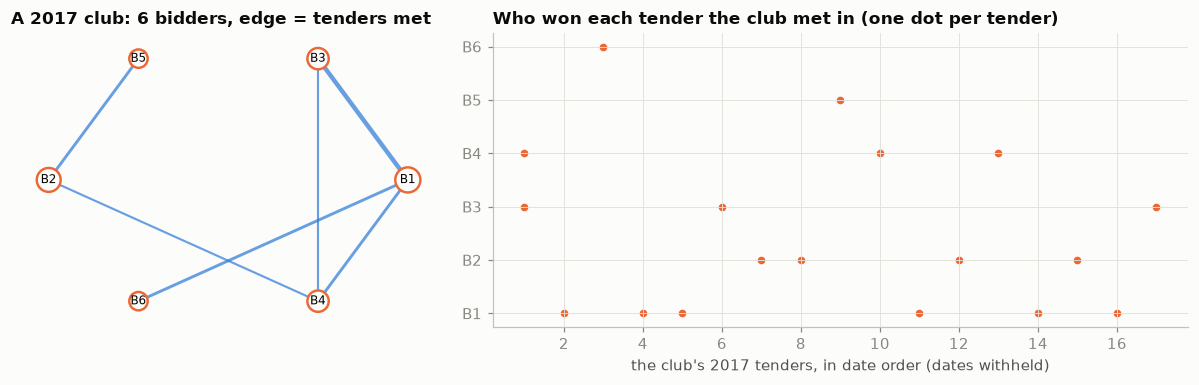

In [11]:
# the picture shows the largest club with no sole trader (natural person) among its members, and no dates (Trap 6)
companies_only = club17[club17.sole_traders == 0]
cid = (companies_only if len(companies_only) else club17).sort_values("contests", ascending=False).index[0]
members = comm17.index[comm17 == cid]
H = G17.subgraph(members)
cb = bids[(bids.m >= month_index(GRAPH_START)) & (bids.m < month_index(GRAPH_END)) & bids.bidder.isin(members)]
won = cb.groupby("bidder").winner.sum().astype(int)
alias = {n: ("sole trader" if is_person_of.get(n, False) else f"B{i+1}")                   # labels valid in this picture only
         for i, n in enumerate(sorted(members, key=lambda n: -won.get(n, 0)))}
contest_lots = cb.groupby("lot").filter(lambda d: len(d) >= 2).lot.unique()
seq = lots.loc[contest_lots].sort_values("date")
tw = cb[cb.lot.isin(seq.index) & (cb.winner == 1)].drop_duplicates(["tender_no", "bidder"])   # one dot per tender and winner
order_no = pd.Series(np.arange(seq.tender_no.nunique()) + 1, index=seq.drop_duplicates("tender_no").tender_no)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 1.6]})
ax = axes[0]
pos = nx.circular_layout(H)
nx.draw_networkx_edges(H, pos, ax=ax, width=[0.4 + 2.5 * d["weight"] / max(w for *_, w in H.edges(data="weight")) for *_, d in H.edges(data=True)],
                       edge_color=SERIES[0], alpha=0.7)
nx.draw_networkx_nodes(H, pos, ax=ax, node_size=[120 + 25 * won.get(n, 0) for n in H], node_color="#fcfcfb", edgecolors=SERIES[1], linewidths=1.6)
nx.draw_networkx_labels(H, pos, labels=alias, ax=ax, font_size=8)
ax.set_title(f"A 2017 club: {len(members)} bidders, edge = tenders met"); ax.axis("off")
ax = axes[1]
w_seq = tw.bidder.map(alias)
order = sorted(set(w_seq))
ax.scatter(tw.tender_no.map(order_no), w_seq.map({a: i for i, a in enumerate(order)}), s=16, color=SERIES[1])
ax.set_yticks(range(len(order)), order); ax.set_xlabel("the club's 2017 tenders, in date order (dates withheld)")
ax.set_title("Who won each tender the club met in (one dot per tender)")
plt.tight_layout()
print(f"{len(companies_only)} of {len(club17)} clubs have no sole trader among their members · club {cid}: "
      f"{seq.tender_no.nunique()} tenders ({len(seq)} lots) in 2017 at {lots.loc[seq.index, 'buyer'].nunique()} buyer(s), "
      f"announced on {seq.date.nunique()} days, "
      f"median final/expected {seq.ratio.median():.3f}, {seq.nc_auction.mean():.0%} of lots with no price drop; tenders won by member: "
      f"{w_seq.value_counts().to_dict()}")

**Reading the picture.** The largest club without a sole trader (5 of 6 qualify): six companies met in 17 tenders in 2017, at two buyers, on 3 announcement days; 89 % of the lots ended within 1 % of the expected value, and the wins rotate 6, 4, 3, 3, 1, 1. Bid rotation, found by structure alone, or six honest local suppliers: only the documents can tell. Dates are withheld (Trap 6).

**The ablation.** Does the graph rank better than per-tender indicators? The measurable target is a proxy close to the collusion story: two or more bidders and a price that barely moved (`nc_auction`). Features are known *before the auction* (per-tender: procedure, value, CPV, region, bidders, pair history, the buyer's past; graph: 2017 communities). Train January–June 2018, test July–December.

In [12]:
# ---- the ablation: per-tender indicators against graph-community features, forward in time ----
PER_TENDER = ["log_value", "ptype_code", "div_no", "region_code", "n_bidders", "month_of_year", "just_below", "max_shared",
              "max_jaccard", "together", "rotation", "cover_present", "bidder_experience", "div_history", "buyer_lots",
              "buyer_single_rate", "buyer_nc_rate"]
GRAPH = ["in_graph", "same_comm_bidders", "all_one_comm", "comm_size", "comm_intensity", "comm_contests", "comm_nc_rate",
         "comm_rotation", "comm_winners", "comm_top_buyer_share", "comm_buyer_share", "in_club"]

def design(idx, comm, ct, buyer_n, club_ids):
    d = S.loc[idx]
    X = pd.DataFrame({"log_value": np.log10(d.value.clip(lower=1)), "ptype_code": d.ptype.cat.codes, "div_no": d.div_no,
                      "region_code": d.buyer_region.cat.codes, "n_bidders": d.n_bidders, "month_of_year": d.date.dt.month,
                      "just_below": FLAGS["bunching"][0](d) & FLAGS["bunching"][1](d),
                      "div_history": np.log1p(d.div_history), "buyer_lots": np.log1p(d.buyer_lots)}, index=idx)
    for c in ["max_shared", "max_jaccard", "together", "rotation", "cover_present", "bidder_experience", "buyer_single_rate", "buyer_nc_rate"]:
        X[c] = d[c].astype(float)
    cf = community_features(idx, comm, ct, buyer_n)
    X["in_club"] = cf.pop("main_comm").isin(club_ids).astype(float)
    X = X.join(cf.astype(float))
    X["comm_size"], X["comm_contests"] = np.log10(X.comm_size), np.log1p(X.comm_contests)
    for c in ["ptype_code", "div_no", "region_code"]:
        X[c] = X[c].astype("category")
    return X

multi18 = S.index[(S.date.dt.year == 2018) & S.multi]
tr_idx = multi18[S.loc[multi18, "date"] < TEST_START]
te_idx = multi18[S.loc[multi18, "date"] >= TEST_START]
y_tr, y_te = S.loc[tr_idx, "nc_auction"].astype(int), S.loc[te_idx, "nc_auction"].astype(int)
K_TEST = REVIEWS_PER_MONTH * 6
HOLDOUT_SHA = hashlib.sha256(pd.util.hash_pandas_object(S.loc[te_idx, ["lot_id", "nc_auction"]], index=False).to_numpy().tobytes()).hexdigest()
t0 = time.time()
X_all = design(multi18, comm17, ct17, bn17, set(club17.index))
print(f"design matrix {X_all.shape} in {time.time()-t0:.0f}s · train Jan–Jun 2018: {len(tr_idx):,} multi-bidder lots ({y_tr.mean():.1%} no price drop) · "
      f"test Jul–Dec 2018: {len(te_idx):,} ({y_te.mean():.1%}) · capacity k = {K_TEST:,} · holdout SHA-256 {HOLDOUT_SHA[:16]}…")

LGB_PARAMS = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=100, subsample=0.8, subsample_freq=1,
                  colsample_bytree=0.8, reg_lambda=5.0, random_state=SEED, n_jobs=N_JOBS, verbose=-1)
def precision_at_k(y, p, k):
    return np.asarray(y)[np.argsort(-np.asarray(p))[:k]].mean()

def fit_eval(X, cols, name):
    m = lgb.LGBMClassifier(**LGB_PARAMS).fit(X.loc[tr_idx, cols], y_tr)
    p = m.predict_proba(X.loc[te_idx, cols])[:, 1]
    return m, p, {"features": name, "AUPRC": average_precision_score(y_te, p), "ROC-AUC": roc_auc_score(y_te, p),
                  f"precision@{K_TEST:,}": precision_at_k(y_te, p, K_TEST)}

m_a, p_a, r_a = fit_eval(X_all, PER_TENDER, "per-tender indicators")
m_b, p_b, r_b = fit_eval(X_all, GRAPH, "graph-community features only")
m_ab, p_ab, r_ab = fit_eval(X_all, PER_TENDER + GRAPH, "per-tender + graph community")
abl = pd.DataFrame([r_a, r_b, r_ab]).set_index("features")
abl.loc["base rate (test)"] = [y_te.mean(), 0.5, y_te.mean()]
free_memory()
display(abl.style.format("{:.3f}"))

design matrix (191140, 29) in 0s · train Jan–Jun 2018: 103,493 multi-bidder lots (20.0% no price drop) · test Jul–Dec 2018: 87,647 (24.0%) · capacity k = 1,200 · holdout SHA-256 d93c081c7c3988fc…


,AUPRC,ROC-AUC,"precision@1,200"
features,,,
per-tender indicators,0.626,0.836,0.946
graph-community features only,0.468,0.737,0.856
per-tender + graph community,0.631,0.838,0.955
base rate (test),0.240,0.500,0.240


AUPRC gain from the graph-community features: +0.005 (95 % bootstrap interval +0.004 to +0.007)
share of the combined model's split gain on graph features: 12% · top five: ptype_code 23%, n_bidders 16%, buyer_nc_rate 12%, div_no 11%, bidder_experience 6%


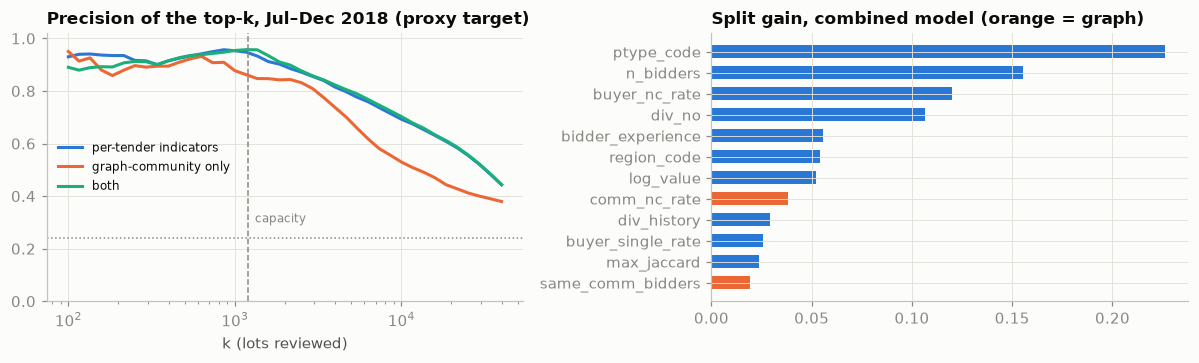

In [13]:
rng = np.random.default_rng(SEED)
yv = y_te.to_numpy()
boot = []
for _ in range(200):                                          # paired bootstrap over test lots
    i = rng.integers(0, len(yv), len(yv))
    boot.append(average_precision_score(yv[i], p_ab[i]) - average_precision_score(yv[i], p_a[i]))
lo_, hi_ = np.percentile(boot, [2.5, 97.5])
print(f"AUPRC gain from the graph-community features: {r_ab['AUPRC'] - r_a['AUPRC']:+.3f} (95 % bootstrap interval {lo_:+.3f} to {hi_:+.3f})")
gain = pd.Series(m_ab.booster_.feature_importance("gain"), index=PER_TENDER + GRAPH)
print(f"share of the combined model's split gain on graph features: {gain[GRAPH].sum() / gain.sum():.0%} · top five: "
      + ", ".join(f"{k} {v:.0%}" for k, v in (gain / gain.sum()).sort_values(ascending=False).head(5).items()))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axes[0]
ks = np.unique(np.geomspace(100, 40_000, 40).astype(int))
for p, lab_, color in [(p_a, "per-tender indicators", SERIES[0]), (p_b, "graph-community only", SERIES[1]), (p_ab, "both", SERIES[2])]:
    ax.plot(ks, [precision_at_k(yv, p, k) for k in ks], lw=2, color=color, label=lab_)
ax.axvline(K_TEST, color=MUTED, ls="--", lw=1); ax.text(K_TEST * 1.1, 0.3, "capacity", color=MUTED, fontsize=8)
ax.axhline(yv.mean(), color=MUTED, ls=":", lw=1); ax.set_xscale("log"); ax.set_ylim(0, 1.02)
ax.set_title("Precision of the top-k, Jul–Dec 2018 (proxy target)"); ax.set_xlabel("k (lots reviewed)"); ax.legend(fontsize=8)
ax = axes[1]
top = (gain / gain.sum()).sort_values(ascending=False).head(12)
ax.barh(top.index[::-1], top.values[::-1], color=[SERIES[1] if f in GRAPH else SERIES[0] for f in top.index[::-1]], height=0.6)
ax.set_title("Split gain, combined model (orange = graph)")
plt.tight_layout()

**Reading the result.** Per-tender indicators reach AUPRC 0.626 against a 24.0 % base rate; the graph alone 0.468, an independent signal; together 0.631, a gain of +0.005 (95 % bootstrap interval +0.004 to +0.007), with 12 % of the split gain on graph features. At 1,200 reviews (six months at 200) precision is 0.946 without the graph and 0.955 with it, a step one seed cannot settle: the top of the queue is easy for any model, as in Task 01. The graph earns its place as an *explanation* (a club is a story an auditor can check) more than as a ranking feature.

## 5 · Validation without labels, and the 200-a-month queue

*Part B · Given model · package `review_queue` and `printable_lead`; C3 asks you to own the queue.*

With no ground truth there is no precision to report. Instead, three properties a valid indicator should have: **stability** (buyers that raise a flag in 2017 raise it in 2018), **agreement** (related flags co-occur, without duplicating each other) and **construct validity** (Fazekas et al., 2016: flagged tenders end at a *higher* share of their expected value than comparable ones).

In [14]:
# ---- 1. stability: does a buyer that raises a flag in 2017 raise it again in 2018? ----
F = fire.join(S.loc[scored, ["buyer_no"]]).assign(year=year)
A = app.join(S.loc[scored, ["buyer_no"]]).assign(year=year)
fs, as_ = F.groupby(["buyer_no", "year"]).sum(), A.groupby(["buyer_no", "year"]).sum()
stab = {}
for k in FLAGS:
    r = (fs[k] / as_[k]).where(as_[k] >= 20).unstack()
    both = r[[2017, 2018]].dropna()
    stab[k] = {"buyers": len(both), "Spearman 2017→2018": spearmanr(both[2017], both[2018]).statistic,
               "Spearman 2018→2019": spearmanr(*r[[2018, 2019]].dropna().T.values).statistic}
cri_b = S.loc[scored].groupby(["buyer_no", year]).cri.agg(["mean", "size"])
cb_ = cri_b["mean"].where(cri_b["size"] >= 20).unstack()
stab["CRI (mean)"] = {"buyers": len(cb_[[2017, 2018]].dropna()), "Spearman 2017→2018": spearmanr(*cb_[[2017, 2018]].dropna().T.values).statistic,
                      "Spearman 2018→2019": spearmanr(*cb_[[2018, 2019]].dropna().T.values).statistic}
display(pd.DataFrame(stab).T.style.format({"buyers": "{:,.0f}", "Spearman 2017→2018": "{:.2f}", "Spearman 2018→2019": "{:.2f}"})
          .set_caption("Buyer-level flag rates, year on year (buyers with >= 20 applicable lots in both years)"))

,buyers,Spearman 2017→2018,Spearman 2018→2019
single_bidder,"1,731",0.56,0.58
price_close,"2,482",0.56,0.59
bunching,"1,722",0.48,0.49
repeat_winner,"1,453",0.43,0.52
together,"1,715",0.38,0.39
rotation,"1,715",0.39,0.35
cover_bidder,"1,715",0.28,0.34
CRI (mean),"2,482",0.64,0.68


,flagged lots compared,"final ÷ expected, flagged","same strata, not flagged",difference (pp of expected value)
single_bidder,"79,508",0.948,0.800,+14.8
bunching,"4,550",0.906,0.875,+3.1
repeat_winner,"13,518",0.929,0.913,+1.6
together,"5,631",0.904,0.874,+3.0
rotation,"2,635",0.895,0.861,+3.4
cover_bidder,"4,661",0.892,0.863,+2.9


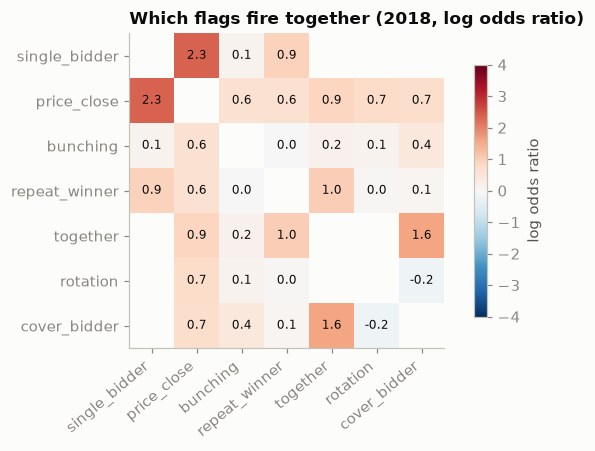

In [15]:
# ---- 2. agreement: log odds ratio between flags, 2018 lots where both apply ----
s18 = scored & (S.date.dt.year == 2018)
f18, a18 = fire[s18[scored].to_numpy()], app[s18[scored].to_numpy()]
names_ = list(FLAGS)
lor = pd.DataFrame(np.nan, index=names_, columns=names_)
for i, a in enumerate(names_):
    for b in names_[i + 1:]:
        m = (a18[a] == 1) & (a18[b] == 1)
        t = pd.crosstab(f18.loc[m, a], f18.loc[m, b]).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
        if (t.values >= 5).all():                               # an empty cell means the pair is exclusive or nested by definition
            lor.loc[a, b] = lor.loc[b, a] = np.log(t.loc[1, 1] * t.loc[0, 0] / (t.loc[1, 0] * t.loc[0, 1]))
# ---- 3. construct validity: do flagged tenders save less than comparable tenders? ----
d18 = S[s18].assign(nb=lambda d: d.n_bidders.clip(upper=5), vband=lambda d: pd.qcut(np.log10(d.value.clip(lower=1)), 10, labels=False))
cv = {}
for k in ["single_bidder", "bunching", "repeat_winner", "together", "rotation", "cover_bidder"]:
    strata = ["ptype", "div_no", "vband"] if k == "single_bidder" else ["ptype", "nb", "div_no"]
    x = d18[a18[k].to_numpy() == 1].assign(flag=f18.loc[a18[k] == 1, k].to_numpy())
    g = x.groupby(strata + ["flag"], observed=True).ratio.agg(["mean", "size"]).unstack("flag").dropna()
    w = g[("size", 1)]
    cv[k] = {"flagged lots compared": int(w.sum()), "final ÷ expected, flagged": np.average(g[("mean", 1)], weights=w),
             "same strata, not flagged": np.average(g[("mean", 0)], weights=w)}
cv = pd.DataFrame(cv).T
cv["difference (pp of expected value)"] = (cv.iloc[:, 1] - cv.iloc[:, 2]) * 100
display(cv.style.format({"flagged lots compared": "{:,.0f}", "final ÷ expected, flagged": "{:.3f}", "same strata, not flagged": "{:.3f}",
                         "difference (pp of expected value)": "{:+.1f}"})
          .set_caption("Within procedure × bidders × CPV division (single bidder: × value decile), 2018"))

fig, ax = plt.subplots(figsize=(6.2, 4.2))
im = ax.imshow(lor.values.astype(float), cmap="RdBu_r", vmin=-4, vmax=4)
ax.set_xticks(range(len(names_)), names_, rotation=40, ha="right"); ax.set_yticks(range(len(names_)), names_)
for i in range(len(names_)):
    for j in range(len(names_)):
        if i != j and pd.notna(lor.iloc[i, j]):
            ax.text(j, i, f"{lor.iloc[i, j]:.1f}", ha="center", va="center", fontsize=8)
ax.grid(False); plt.colorbar(im, ax=ax, shrink=0.8, label="log odds ratio")
ax.set_title("Which flags fire together (2018, log odds ratio)")
plt.tight_layout()

**Reading the three checks.** Buyer-level rates are moderately stable (Spearman 0.28–0.56 per flag, 0.64 for the CRI). The strongest agreement is mechanical: one bidder and a price at the reserve (log odds ratio 2.3). `together` agrees with `cover_bidder` (1.6) and `repeat_winner` (1.0), as a cartel story predicts; `rotation` and `cover_bidder` do not (−0.2); blank cells are exclusive or nested by definition. Construct validity holds for every flag: flagged lots end 1.6–3.4 points of the expected value above comparable lots, single-bidder lots 14.8 points above. That fits weaker competition, not proven fraud.

**What a real evaluation needs.** We did not hand-label tenders: without the documents, a label would only restate the flags. The honest design is a *review protocol*: auditors review the queue *and* a blind random sample of unflagged lots, two reviewers on a subset (Cohen's κ), giving precision at 200 and the base rate. Public outcomes can seed weak labels: State Audit Service conclusions and Antimonopoly Committee bid-rigging decisions (E2).

**The operating point.** Five ways to spend 200 reviews a month in 2018:

,mean flags,>= 3 flags,multi-bidder,collusion flag,2017 club,"value, UAH m",buyers,top CPV division
biggest expected value first (no flags),0.64,3%,98%,10.7%,0.0%,"262,732",591,55%
CRI: share of applicable flags,3.02,95%,11%,11.4%,0.0%,"3,351","1,264",13%
weighted flags,2.69,61%,96%,96.4%,0.3%,"37,085",729,22%
weighted flags + graph club,2.69,61%,96%,96.4%,0.5%,"37,077",728,22%
"weighted flags, max 3 per buyer a month",2.61,54%,91%,90.0%,0.4%,"22,423",966,22%


2018: 22,567 competitive lots a month; 525 a month raise >= 3 flags and 4,193 raise >= 2, against capacity 200 · 32 lots in 2017 clubs · adding the club term changes 0.2% of the weighted queue


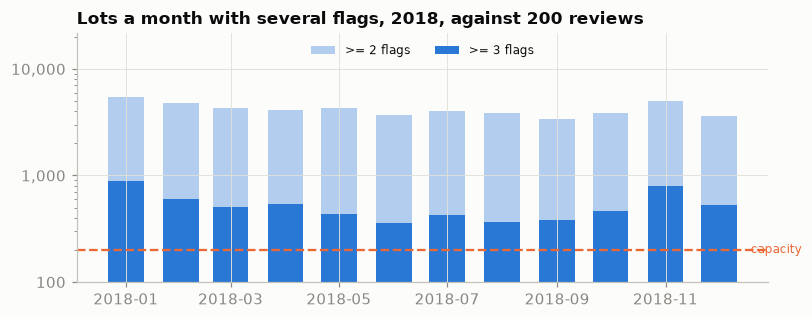

In [16]:
# ---- the operating point: REVIEWS_PER_MONTH tenders a month, chosen five ways (2018) ----
d18 = S[s18].copy()
cf18 = community_features(d18.index[d18.multi], comm17, ct17, bn17)
d18["club"] = cf18.main_comm.isin(set(club17.index)).reindex(d18.index, fill_value=False)   # graph: bidders form a 2017 club
d18["score_graph"] = d18.red_flag_score + WEIGHTS["rotation"] * d18.club
d18["collusion_flag"] = (f18[["together", "rotation", "cover_bidder"]].sum(axis=1) > 0).to_numpy()
def review_queue(d, keys, cap_per_buyer=None):
    d = d.sort_values(keys, ascending=False)
    if cap_per_buyer:
        d = d[d.groupby(["m", "buyer_no"]).cumcount() < cap_per_buyer]
    return d.groupby("m").head(REVIEWS_PER_MONTH)
policies = {"biggest expected value first (no flags)": review_queue(d18, ["value"]),
            "CRI: share of applicable flags": review_queue(d18, ["cri", "n_flags", "value"]),
            "weighted flags": review_queue(d18, ["red_flag_score", "value"]),
            "weighted flags + graph club": review_queue(d18, ["score_graph", "value"]),
            "weighted flags, max 3 per buyer a month": review_queue(d18, ["red_flag_score", "value"], cap_per_buyer=3)}
qt = pd.DataFrame({name: {"mean flags": q.n_flags.mean(), ">= 3 flags": (q.n_flags >= 3).mean(), "multi-bidder": q.multi.mean(),
                          "collusion flag": q.collusion_flag.mean(), "2017 club": q.club.mean(),
                          "value, UAH m": q.value.sum() / 1e6, "buyers": q.buyer_no.nunique(),
                          "top CPV division": q.cpv2.value_counts(normalize=True).iloc[0]} for name, q in policies.items()}).T
display(qt.style.format({"mean flags": "{:.2f}", ">= 3 flags": "{:.0%}", "multi-bidder": "{:.0%}", "collusion flag": "{:.1%}",
                         "2017 club": "{:.1%}", "value, UAH m": "{:,.0f}", "buyers": "{:,.0f}", "top CPV division": "{:.0%}"})
          .set_caption(f"{REVIEWS_PER_MONTH} reviews a month, 2018 ({12 * REVIEWS_PER_MONTH:,} tenders per policy)"))
q_main = policies["weighted flags"]
ov = len(set(q_main.index) & set(policies["weighted flags + graph club"].index)) / len(q_main)
per_month = d18.groupby("m").agg(ge3=("n_flags", lambda s: (s >= 3).sum()), ge2=("n_flags", lambda s: (s >= 2).sum()))
print(f"2018: {len(d18) / 12:,.0f} competitive lots a month; {int(per_month.ge3.mean()):,} a month raise >= 3 flags and {int(per_month.ge2.mean()):,} raise >= 2, against capacity "
      f"{REVIEWS_PER_MONTH} · {d18.club.sum():,} lots in 2017 clubs · adding the club term changes "
      f"{1 - ov:.1%} of the weighted queue")

fig, ax = plt.subplots(figsize=(7.5, 3.0))
mm = pd.period_range("2018-01", periods=12, freq="M").to_timestamp()
ax.bar(mm, per_month.ge2.values, width=20, color=SERIES[0], alpha=0.35, label=">= 2 flags")
ax.bar(mm, per_month.ge3.values, width=20, color=SERIES[0], label=">= 3 flags")
ax.axhline(REVIEWS_PER_MONTH, color=SERIES[1], lw=1.5, ls="--")
ax.text(mm[-1] + pd.Timedelta(days=18), REVIEWS_PER_MONTH, "capacity", color=SERIES[1], fontsize=8, va="center")
ax.set_yscale("log"); ax.set_ylim(100, per_month.ge2.max() * 4)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}")); ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_title("Lots a month with several flags, 2018, against 200 reviews"); ax.legend(loc="upper center", ncol=2, fontsize=8)
plt.tight_layout()

**Reading the queue table.** The biggest contracts cover UAH 262.7 bn, but only 3 % raise three or more flags. The CRI queue fails the other way: 95 % raise three flags, but 89 % are single-bidder lots, whose fewer applicable flags inflate the *share* that fires: a bias of the index. The weighted score sends 96 % of reviews to multi-bidder lots with a collusion flag and still covers UAH 37.1 bn; the club term changes 0.2 % of it; a cap of three per buyer spreads reviews over 966 buyers instead of 729. Capacity binds: 525 lots a month raise three or more flags. Our starting ADR is the weighted score with the cap (C3).

In [17]:
# ---- what may leave the audit system: a minimised lead (the input to the Stretch GenAI brief; see Trap 6) ----
FLAG_TEXT = {"single_bidder": "one bidder", "price_close": f"final price >= {PRICE_CLOSE:.0%} of the expected value",
             "bunching": f"expected value within {BUNCH_BAND:.0%} under the open-tender threshold",
             "repeat_winner": f"winner took >= {REPEAT_MIN_SHARE:.0%} of this buyer's lots in the CPV division over the previous 12 months",
             "together": "two bidders who bid mostly with each other (prior 12 months)",
             "rotation": "an always-together pair that takes turns winning", "cover_bidder": "a loser that bids often and never wins"}
VALUE_BANDS = [0, 10_000, 50_000, 200_000, 1_500_000, 10_000_000, np.inf]
S["value_band"] = pd.cut(S.value, VALUE_BANDS, labels=["under 10k", "10k–50k", "50k–200k", "200k–1.5m", "1.5m–10m", "over 10m"], right=False)
S["month"] = S.date.dt.to_period("M")
S["fall_5pc"] = (((1 - S.ratio) * 20).round() * 5).astype("float32")      # price fall, rounded to 5 points
QI_PRINTED = ["month", "ptype", "cpv2", "buyer_type", "value_band", "fall_5pc"]
has_person = bids.groupby("lot").is_person.any().reindex(S.index, fill_value=False)

def k_anonymity(idx, cols):
    """For each lot: how many lots in the scored extract share its values on cols (k = 1 means it is unique)."""
    g = S.loc[scored].groupby(cols, observed=True).size()
    return g.reindex(pd.MultiIndex.from_frame(S.loc[idx, cols])).fillna(0).astype(int).to_numpy()

def evidence(lot):
    """Counts behind the pair and repeat-winner flags; the record IDs stay inside the audit system."""
    r, b = S.loc[lot], bids[bids.lot == lot]
    hist = bids[(bids.m < r.m) & (bids.m >= r.m - HISTORY_MONTHS) & bids.bidder.isin(b.bidder)].groupby("bidder").tender_no.apply(set)
    met = [len(hist.get(a_, set()) & hist.get(b_, set())) for a_, b_ in lot_pairs[lot_pairs.lot == lot][["a", "b"]].itertuples(index=False)]
    same = ((lots.buyer_no == r.buyer_no) & (lots.div_no == r.div_no) & (lots.winner == r.winner)
            & (lots.m < r.m) & (lots.m >= r.m - HISTORY_MONTHS)).sum()
    return max(met, default=0), int(same)

def printable_lead(lot):
    """The lead as it may be shown outside the audit system: no natural person, no record ID, coarse quasi-identifiers."""
    r, b = S.loc[lot], bids[bids.lot == lot]
    firms = b[~b.is_person]                                             # winner first (bids are sorted that way)
    k = int(k_anonymity([lot], QI_PRINTED)[0])
    assert k >= K_MIN, f"lead {lot} is identifiable (k = {k}); coarsen further before printing"
    n_pair, n_same = evidence(lot)
    return {"record": "held in the audit system, not printed", "announced": f"{r.date:%Y-%m}", "procedure": str(r.ptype),
            "item": f"CPV division {r.cpv2} · {CPV.get(str(r.cpv2), '?')}", "buyer type": str(r.buyer_type),
            "expected value, UAH": str(r.value_band), "price fall vs expected": f"about {r.fall_5pc:.0f} %",
            "bidders": [f"company {chr(65 + i)}" + (" (winner)" if w else "") for i, w in enumerate(firms.winner)]
                       + ([f"{int(b.is_person.sum())} sole trader(s), never listed"] if b.is_person.any() else []),
            "flags": [f"{FLAG_TEXT[k_]} ({WEIGHTS[k_]:.1f} bits)" for k_ in FLAGS if fire.loc[lot, k_]],
            "score": round(float(r.red_flag_score), 1),
            "evidence": {"tenders the flagged pair met in, previous 12 months": n_pair,
                         "lots this buyer gave the same winner in this CPV division, previous 12 months": n_same},
            "k-anonymity in the extract": k}

cand = q_main[q_main.collusion_flag & ~has_person.reindex(q_main.index).to_numpy()].sort_values(["red_flag_score", "value"], ascending=False)
cand = cand[k_anonymity(cand.index, QI_PRINTED) >= K_MIN]
print(f"{has_person.reindex(q_main.index).mean():.0%} of the weighted 2018 queue has a sole-trader bidder; "
      f"the example is the top-scored lead with none whose printed fields match >= {K_MIN} lots")
print(json.dumps(printable_lead(cand.index[0]), indent=1, ensure_ascii=False))

28% of the weighted 2018 queue has a sole-trader bidder; the example is the top-scored lead with none whose printed fields match >= 10 lots


{
 "record": "held in the audit system, not printed",
 "announced": "2018-07",
 "procedure": "Above Threshold EU",
 "item": "CPV division 45000000-7 · Construction work",
 "buyer type": "state administration",
 "expected value, UAH": "over 10m",
 "price fall vs expected": "about 0 %",
 "bidders": [
  "company A (winner)",
  "company B",
  "company C",
  "company D"
 ],
 "flags": [
  "final price >= 99% of the expected value (1.9 bits)",
  "two bidders who bid mostly with each other (prior 12 months) (4.9 bits)",
  "an always-together pair that takes turns winning (6.5 bits)",
  "a loser that bids often and never wins (5.7 bits)"
 ],
 "score": 19.0,
 "evidence": {
  "tenders the flagged pair met in, previous 12 months": 153,
  "lots this buyer gave the same winner in this CPV division, previous 12 months": 95
 },
 "k-anonymity in the extract": 14
}


This **minimised lead** is what may leave the audit system: month, CPV division, value band, price fall to 5 points, companies relabelled per lead, sole traders counted but never listed, evidence as counts, no record ID, and at least `K_MIN` = 10 matching lots. Why: a sole trader is a natural person, and a collusion flag beside an identifiable person is personal data about suspected wrongdoing (Ukraine's Law No. 2297-VI, or GDPR for an EU body; our reading).

## 6 · The traps ⚠

*Part B · Given model · read; C1 turns each trap into a test.*

Six ways a careless version of this notebook builds a tidier queue, or a riskier one, each measured.

**Trap 1 — Entity resolution: whose bid is it?** Cleaning codes (leading zeros, suffixes) merges 11 raw codes. 517 lots list the same firm twice; counting rows instead of firms hides 111 single-bidder lots. Each code has one name, but 720 normalised names are shared by 1,596 codes. Merging on name would turn 21 two-bidder lots into single-bidder ones and erase the 95 lots where two *different* codes with the same name bid against each other, which end with no price drop 27 % of the time against 19 % of multi-bidder lots: possibly affiliated firms, a lead rather than a duplicate. Key on the cleaned code, keep names as evidence, let the business register decide (E1).

In [18]:
# ---- Trap 1: entity resolution ----
kinds = pd.Series(META["code_kinds"])
le = bids.loc[~bids.is_person & bids.core.astype(str).ne(""), ["lot", "bidder", "form", "core"]]
ident_ = le.drop_duplicates("bidder")
by_core = ident_.groupby("core", observed=True).bidder.size()
by_name = ident_.groupby(["form", "core"], observed=True).bidder.size()
led = le.drop_duplicates(["lot", "bidder"])
sn_lots = led.loc[led.duplicated(["lot", "form", "core"]), "lot"].unique()
multi_all = S.index[S.multi & scored]
twice = S.n_rows > S.n_bidders
print(f"codes: {kinds.get('edrpou_lost_zeros', 0)} lost their leading zeros, {kinds.get('edrpou_suffix', 0)} carry a suffix, "
      f"{kinds.get('other', 0)} are foreign or malformed, {kinds.get('person_passport', 0)} are passport numbers · cleaning merges "
      f"{bids.bidder_raw.nunique() - bids.bidder.nunique()} raw codes")
print(f"one firm listed twice in the same lot: {int(twice.sum())} lots ({int(bids.duplicated(['lot', 'bidder_raw']).sum())} with the identical raw code) · "
      f"counting rows instead of firms hides {int((twice & (S.n_bidders == 1)).sum())} single-bidder lots, "
      f"{int((twice & (S.n_bidders == 1) & S.ptype.str.startswith('Above')).sum())} of them in above-threshold procedures that need two bidders")
print(f"names: {(by_name > 1).sum():,} normalised names are shared by {by_name[by_name > 1].sum():,} different codes "
      f"({(by_core > 1).sum():,} names / {by_core[by_core > 1].sum():,} codes if the legal form is ignored) · "
      f"merging on name would turn {S.loc[sn_lots].query('n_bidders == 2').shape[0]:,} two-bidder lots into single-bidder lots")
print(f"lots where two different codes with the same normalised name bid against each other: {len(sn_lots):,} · "
      f"no price drop in {S.loc[sn_lots, 'nc_auction'].mean():.0%} of them against {S.loc[multi_all, 'nc_auction'].mean():.0%} "
      f"of all multi-bidder lots · Latin look-alike letters inside Cyrillic names: {META['mixed_script_names']:,} names")

codes: 62 lost their leading zeros, 3 carry a suffix, 388 are foreign or malformed, 15 are passport numbers · cleaning merges 11 raw codes


one firm listed twice in the same lot: 517 lots (515 with the identical raw code) · counting rows instead of firms hides 111 single-bidder lots, 0 of them in above-threshold procedures that need two bidders
names: 720 normalised names are shared by 1,596 different codes (1,148 names / 2,700 codes if the legal form is ignored) · merging on name would turn 21 two-bidder lots into single-bidder lots
lots where two different codes with the same normalised name bid against each other: 95 · no price drop in 27% of them against 19% of all multi-bidder lots · Latin look-alike letters inside Cyrillic names: 1,116 names


**Trap 2 — The law decides where a flag can fire.** Since one-bidder open tenders are cancelled (our reading of Article 31), a pooled single-bidder rate measures the procedure mix. From 2016 Q1 to 2017 Q4 it rose from 30.6 % to 34.5 %; below the threshold, from 30.6 % to 49.7 %, while the above-threshold share went from 0 % to 31 %. Across CPV divisions in 2018 the pooled rate correlates −0.49 with the above-threshold share and agrees with the below-threshold ranking at only 0.52 (food falls from 6th to 13th).

In [19]:
# ---- Trap 2: the law decides where a flag can fire ----
qq = S.loc[scored, ["date", "single", "ptype", "cpv2"]].assign(q=S.date[scored].dt.to_period("Q"))
pooled = qq.groupby("q").single.mean()
below_only = qq[qq.ptype == "Below Threshold"].groupby("q").single.mean()
share_above = qq.groupby("q").ptype.apply(lambda s: s.str.startswith("Above").mean())
print(f"single-bidder rate, 2016Q1 → 2017Q4: pooled {pooled.iloc[0]:.1%} → {pooled.loc['2017Q4']:.1%}; below-threshold only "
      f"{below_only.iloc[0]:.1%} → {below_only.loc['2017Q4']:.1%}; above-threshold share of lots {share_above.iloc[0]:.1%} → {share_above.loc['2017Q4']:.1%}")
dv = qq[qq.date.dt.year == 2018].groupby("cpv2", observed=True).agg(n=("single", "size"), pooled=("single", "mean"),
                                                                    above=("ptype", lambda s: s.str.startswith("Above").mean()))
dv["below_only"] = qq[(qq.date.dt.year == 2018) & (qq.ptype == "Below Threshold")].groupby("cpv2", observed=True).single.mean()
dv = dv[dv.n >= 1000].dropna()
dv["name"] = [CPV.get(str(c), "?")[:38] for c in dv.index]
print(f"2018, {len(dv)} CPV divisions with >= 1,000 lots: rank correlation of the pooled and the below-threshold single-bidder rate "
      f"{spearmanr(dv.pooled, dv.below_only).statistic:.2f}; correlation of the pooled rate with the above-threshold share "
      f"{spearmanr(dv.pooled, dv.above).statistic:.2f}")
display(dv.assign(rank_pooled=dv.pooled.rank(ascending=False), rank_below=dv.below_only.rank(ascending=False))
          .sort_values("rank_pooled").head(6)[["name", "pooled", "below_only", "above", "rank_pooled", "rank_below"]]
          .style.format({"pooled": "{:.0%}", "below_only": "{:.0%}", "above": "{:.0%}", "rank_pooled": "{:.0f}", "rank_below": "{:.0f}"}))

single-bidder rate, 2016Q1 → 2017Q4: pooled 30.6% → 34.5%; below-threshold only 30.6% → 49.7%; above-threshold share of lots 0.0% → 31.0%
2018, 31 CPV divisions with >= 1,000 lots: rank correlation of the pooled and the below-threshold single-bidder rate 0.52; correlation of the pooled rate with the above-threshold share -0.49


,name,pooled,below_only,above,rank_pooled,rank_below
cpv2,,,,,,
72000000-5,"IT services: consulting, software deve",58%,80%,28%,1,3
98000000-3,"Other community, social and personal s",56%,77%,27%,2,4
45000000-7,Construction work,40%,68%,41%,3,6
60000000-8,Transport services (excl. Waste transp,39%,75%,48%,4,5
50000000-5,Repair and maintenance services,36%,63%,43%,5,7
15000000-8,"Food, beverages, tobacco and related p",35%,49%,29%,6,13


**Trap 3 — Base rates: a raw rate compares different markets.** Standardised against what a lot *is* (procedure × CPV division × value decile), the regional ranking by single-bidder rate changes a lot (rank correlation 0.60; one region moves 15 places): Poltava's 6.1 % is half what its mix predicts. The weighted score is sturdier (0.95); standardising changes 16 % of the queue.

In [20]:
# ---- Trap 3: base rates by region and category ----
d18["vband"] = pd.qcut(np.log10(d18.value.clip(lower=1)), 10, labels=False)
mix_keys = ["ptype", "div_no", "vband"]                            # what a lot is: procedure, CPV division, value decile
reg = d18.groupby("buyer_region", observed=True).agg(lots=("single", "size"), single_raw=("single", "mean"), score_raw=("red_flag_score", "mean"))
reg["single_expected"] = d18.groupby(mix_keys, observed=True).single.transform("mean").groupby(d18.buyer_region, observed=True).mean()
expct = d18.groupby(mix_keys, observed=True).red_flag_score.transform("mean")
reg["score_expected"] = expct.groupby(d18.buyer_region, observed=True).mean()
reg = reg[reg.lots >= 1000]
reg["single O/E"], reg["score O/E"] = reg.single_raw / reg.single_expected, reg.score_raw / reg.score_expected
mv = lambda a, b: int((reg[a].rank(ascending=False) - reg[b].rank(ascending=False)).abs().max())
print(f"{len(reg)} regions with >= 1,000 lots in 2018 · single-bidder rate: rank correlation raw vs standardised "
      f"{spearmanr(reg.single_raw, reg['single O/E']).statistic:.2f}, largest move {mv('single_raw', 'single O/E')} places · "
      f"weighted score: {spearmanr(reg.score_raw, reg['score O/E']).statistic:.2f}, largest move {mv('score_raw', 'score O/E')} places")
display(reg.sort_values("single_raw", ascending=False).iloc[[0, 1, 2, -3, -2, -1]][["lots", "single_raw", "single_expected", "single O/E", "score O/E"]]
          .style.format({"lots": "{:,}", "single_raw": "{:.1%}", "single_expected": "{:.1%}", "single O/E": "{:.2f}", "score O/E": "{:.2f}"}))
d18["score_within"] = d18.red_flag_score - expct                  # excess over comparable lots
q_std = review_queue(d18, ["score_within", "red_flag_score"])
top_div = lambda q: q.cpv2.value_counts(normalize=True)
print(f"queue share of the three largest CPV divisions: raw score {top_div(q_main).head(3).sum():.0%} "
      f"({', '.join(re.split(r',| and ', CPV.get(str(c), '?'))[0].lower() for c in top_div(q_main).head(3).index)}), standardised {top_div(q_std).head(3).sum():.0%} · "
      f"overlap of the two queues {len(set(q_main.index) & set(q_std.index)) / len(q_main):.0%}")

24 regions with >= 1,000 lots in 2018 · single-bidder rate: rank correlation raw vs standardised 0.60, largest move 15 places · weighted score: 0.95, largest move 5 places


,lots,single_raw,single_expected,single O/E,score O/E
buyer_region,,,,,
Zhytomyr,"10,764",39.6%,37.7%,1.05,0.85
Chernihiv,"9,832",38.1%,37.4%,1.02,1.07
Vinnytsia,"15,828",37.7%,36.3%,1.04,0.98
Zakarpattia,"1,890",12.0%,12.2%,0.98,0.71
Kherson,"3,678",6.4%,7.3%,0.87,1.14
Poltava,"4,435",6.1%,12.8%,0.48,0.85


queue share of the three largest CPV divisions: raw score 51% (food, construction work, transport equipment), standardised 47% · overlap of the two queues 84%


**Trap 4 — Information from after the award.** Compute pair history over the whole extract instead of the 12 months before each lot, and the 2018 rates barely move (`together` 2.9 % against 2.8 %) but the queue overlap is 48 %: a longer look-back and the future together change half the queue (C1 separates them). Letting community statistics run to December 2018, so they include the test lots' outcomes, lifts AUPRC from 0.631 to 0.635 and precision@1,200 from 0.955 to 0.959: small, and exactly what a fixed gate rewards. The as-of rule needs a test (C1).

In [21]:
# ---- Trap 4: information from after the award ----
PW_all, BW_all = pair_month.drop(columns="m").groupby(["a", "b"]).sum(), bidder_month.drop(columns="m").groupby("bidder").sum()
q = lot_pairs[lot_pairs.lot.isin(d18.index)].join(PW_all, on=["a", "b"]).join(BW_all.add_suffix("_a"), on="a").join(BW_all.add_suffix("_b"), on="b")
q["jaccard"] = q.shared / (q.bids_a + q.bids_b - q.shared).clip(lower=1)
q["together"] = (q.shared >= PAIR_MIN_TENDERS) & (q.jaccard >= PAIR_MIN_JACCARD)
q["rotation"] = q.together & (q.wa >= ROTATION_MIN_SHARE * q.shared) & (q.wb >= ROTATION_MIN_SHARE * q.shared)
leak = q.groupby("lot")[["together", "rotation"]].max().reindex(d18.index[d18.multi], fill_value=False)
d_leak = d18.copy()
for k in ["together", "rotation"]:
    d_leak[k] = leak[k].reindex(d_leak.index, fill_value=False)
f_leak, _, _ = score(d_leak)
d_leak["red_flag_score"] = (f_leak * WEIGHTS).sum(axis=1)
q_leak = review_queue(d_leak, ["red_flag_score", "value"])
print(f"2018 multi-bidder lots flagged 'together': as-of {d18.loc[d18.multi, 'together'].mean():.1%}, whole extract {leak.together.mean():.1%}; "
      f"'rotation': {d18.loc[d18.multi, 'rotation'].mean():.1%} vs {leak.rotation.mean():.1%} · queue overlap {len(set(q_main.index) & set(q_leak.index)) / len(q_main):.0%}")
ct_leak, bn_leak = community_table(G17, comm17, month_index(GRAPH_START), month_index(TEST_END))   # stats include the test lots
X_leak = design(multi18, comm17, ct_leak, bn_leak, set(clubs(ct_leak).index))
_, p_leak, r_leak = fit_eval(X_leak, PER_TENDER + GRAPH, "per-tender + graph community, stats through Dec 2018 ⚠")
display(pd.DataFrame([r_ab, r_leak]).set_index("features").style.format("{:.3f}"))
del X_leak, d_leak, f_leak, q, leak, PW_all, BW_all; free_memory()

2018 multi-bidder lots flagged 'together': as-of 2.9%, whole extract 2.8%; 'rotation': 1.4% vs 1.3% · queue overlap 48%


,AUPRC,ROC-AUC,"precision@1,200"
features,,,
per-tender + graph community,0.631,0.838,0.955
"per-tender + graph community, stats through Dec 2018 ⚠",0.635,0.839,0.959


**Trap 5 — A lot is not a tender.** Count each lot of a multi-lot tender as a meeting and two firms bidding on five lots of one tender meet five times: the `together` rate rises from 2.95 % to 3.47 % of 2018 multi-bidder lots (+18 %). Our own first draft fell into it: counting lots finds 17 clubs, counting tenders 6, and the largest lot-counted "club" met in 104 lots but only 4 tenders.

In [22]:
# ---- Trap 5: a tender with several lots is one meeting, not several ----
pm_lot = lot_pairs.groupby(["a", "b", "m"]).size().rename("shared").reset_index().assign(wa=0, wb=0)
bm_lot = bids.groupby(["bidder", "m"]).agg(bids=("lot", "size"), wins=("winner", "sum")).reset_index()
ct_lots, _ = community_table(G17, comm17, month_index(GRAPH_START), month_index(GRAPH_END), unit="lot")
club_lots = clubs(ct_lots)
big = club_lots.contests.idxmax()
print(f"clubs (>= {CLUB['min_contests']} internal contests): counting tenders {len(club17)}, counting lots {len(club_lots)}, "
      f"{len(set(club_lots.index) & set(club17.index))} in both · the largest lot-counted club met in {int(club_lots.contests.max())} lots "
      f"but {int(ct17.loc[big, 'contests'])} tenders")
tog_lot = pd.concat([asof_features(M, pm=pm_lot, bm=bm_lot)[["together", "max_shared"]]
                     for M in range(month_index(TRAIN_START), month_index(TEST_END))])
mi = d18.index[d18.multi]
print(f"2018 multi-bidder lots flagged 'together': counting tenders {d18.loc[mi, 'together'].mean():.2%}, counting lots "
      f"{tog_lot.together.reindex(mi).fillna(False).astype(bool).mean():.2%} · median shared history {d18.loc[mi, 'max_shared'].median():.0f} vs "
      f"{tog_lot.max_shared.reindex(mi).median():.0f} · {S.loc[scored].groupby('tender_no').size().gt(1).sum():,} tenders have several lots")
del pm_lot, bm_lot, tog_lot; free_memory()

clubs (>= 10 internal contests): counting tenders 6, counting lots 17, 6 in both · the largest lot-counted club met in 104 lots but 4 tenders


2018 multi-bidder lots flagged 'together': counting tenders 2.95%, counting lots 3.47% · median shared history 5 vs 5 · 29,768 tenders have several lots


**Trap 6 — A masked lead can still point at a person.** Our first draft masked the buyer's name and record ID but printed the date, CPV code, region and both values: unique in the extract for 95 % of the 2,400 queued leads (82 % on the two values alone), and ProZorro is public. 373 sole traders bid in 667 of those leads. The minimised fields give a median k of 11; only 52 % of leads reach k ≥ 10, so the rest need more coarsening before they leave the audit system (C1).

In [23]:
# ---- Trap 6: re-identification of printed leads ----
QI_FIRST_DRAFT = ["date", "cpv", "buyer_region", "buyer_type", "value", "final_value"]   # the first draft's pack, IDs and names masked
k_naive, k_val, k_min = (k_anonymity(q_main.index, c) for c in [QI_FIRST_DRAFT, ["value", "final_value"], QI_PRINTED])
qp = bids[bids.lot.isin(q_main.index) & bids.is_person]
print(f"weighted 2018 queue, {len(q_main):,} leads: {qp.bidder.nunique():,} distinct sole traders bid in {qp.lot.nunique():,} of them")
print(f"unique in the extract (k = 1) on the first draft's fields: {(k_naive == 1).mean():.0%} of leads; on the two values alone: "
      f"{(k_val == 1).mean():.0%} · on the printed fields: median k {np.median(k_min):,.0f}, {(k_min >= K_MIN).mean():.0%} of leads reach k >= {K_MIN}")

weighted 2018 queue, 2,400 leads: 373 distinct sole traders bid in 667 of them
unique in the extract (k = 1) on the first draft's fields: 95% of leads; on the two values alone: 82% · on the printed fields: median k 11, 52% of leads reach k >= 10


# Part C — Productionise it

*Sections 7–10: this is your assignment.*

## 7 · After deployment: the procedure mix moves, the flags hold

*Part C · Productionise · what your monitoring plan must catch (C5, E4); reuse `psi`.*

Freeze the 2017 definitions and weights and watch the stream through 2019: inputs and flag rates now, auditors' findings months later.

,lots,PSI score,PSI bidders,PSI log value,above-threshold share
q,,,,,
2016Q1,"22,914",0.094,0.182,0.753,0.0%
2016Q3,"49,663",0.043,0.031,0.120,13.8%
2017Q1,"74,926",0.006,0.007,0.006,30.8%
2017Q3,"62,300",0.001,0.000,0.002,31.8%
2018Q1,"78,431",0.003,0.003,0.023,36.4%
2018Q3,"58,676",0.016,0.003,0.044,39.7%
2019Q1,"72,425",0.014,0.010,0.082,42.3%
2019Q3,"53,343",0.020,0.021,0.082,46.0%


2017 Q1 – 2019 Q4: highest PSI of the score 0.020, of the bidder count 0.021, of log value 0.104 (2019Q4)
non-open procedures' share of awarded value: 31% in 2016, 20% in 2019 · weighted-score queue cut-off by quarter: 2017Q1 10.4, 2018Q1 11.5, 2019Q1 11.4


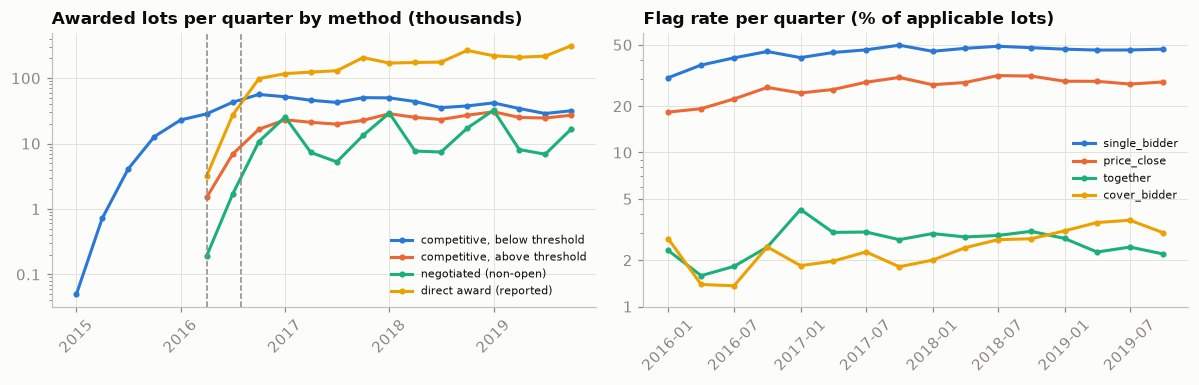

In [24]:
grp = {"Below Threshold": "competitive, below threshold", "Above Threshold UA": "competitive, above threshold",
       "Above Threshold EU": "competitive, above threshold", "Above Threshold UA Defense": "competitive, above threshold",
       "Negotiation": "negotiated (non-open)", "Quick Negotiation": "negotiated (non-open)", "Reporting": "direct award (reported)"}
mq = mix_q.assign(group=mix_q.ptype.astype(str).map(grp)).groupby(["quarter", "group"]).agg(lots=("lots", "sum"), value=("value", "sum")).unstack()
vq = (mq["value"].T / mq["value"].sum(axis=1)).T
rq = fire.groupby(S.date[scored].dt.to_period("Q")).sum() / app.groupby(S.date[scored].dt.to_period("Q")).sum()

def psi(ref, cur, bins=10):
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
    r = np.histogram(ref, edges)[0] / len(ref) + 1e-6
    c = np.histogram(cur, edges)[0] / len(cur) + 1e-6
    return float(np.sum((c - r) * np.log(c / r)))
sq = S.loc[scored, ["date", "red_flag_score", "n_bidders", "ptype", "m"]].assign(q=S.date[scored].dt.to_period("Q"), lv=np.log10(S.value[scored].clip(lower=1)))
ref = sq[sq.date.dt.year == GRAPH_START.year]
drift = sq.groupby("q").apply(lambda d: pd.Series({"lots": len(d), "PSI score": psi(ref.red_flag_score, d.red_flag_score),
                                                    "PSI bidders": psi(ref.n_bidders, d.n_bidders), "PSI log value": psi(ref.lv, d.lv),
                                                    "above-threshold share": d.ptype.str.startswith("Above").mean()}), include_groups=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
t_ = mq.index.to_timestamp()
for c, color in zip(["competitive, below threshold", "competitive, above threshold", "negotiated (non-open)", "direct award (reported)"], SERIES):
    ax.plot(t_, mq[("lots", c)] / 1e3, "-o", ms=3, lw=2, color=color, label=c)
for d_, lab_ in [("2016-04-01", "central bodies"), ("2016-08-01", "everyone")]:
    ax.axvline(pd.Timestamp(d_), color=MUTED, ls="--", lw=1)
ax.set_yscale("log"); ax.set_title("Awarded lots per quarter by method (thousands)"); ax.legend(fontsize=7)
ax = axes[1]
t2 = rq.index.to_timestamp()
for k, color in zip(["single_bidder", "price_close", "together", "cover_bidder"], SERIES):
    ax.plot(t2, rq[k] * 100, "-o", ms=3, lw=2, color=color, label=k)
ax.set_yscale("log"); ax.set_title("Flag rate per quarter (% of applicable lots)"); ax.legend(fontsize=7)
for a in axes:
    a.tick_params(axis="x", rotation=45)
    a.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}")); a.yaxis.set_minor_formatter(NullFormatter())
ax.set_yticks([1, 2, 5, 10, 20, 50])
plt.tight_layout()
display(drift.loc["2016Q1":].iloc[::2].style.format({"lots": "{:,.0f}", "PSI score": "{:.3f}", "PSI bidders": "{:.3f}",
                                                    "PSI log value": "{:.3f}", "above-threshold share": "{:.1%}"}))
late = drift.loc["2017Q1":]
print(f"2017 Q1 – 2019 Q4: highest PSI of the score {late['PSI score'].max():.3f}, of the bidder count {late['PSI bidders'].max():.3f}, "
      f"of log value {late['PSI log value'].max():.3f} ({late['PSI log value'].idxmax()})")
print(f"non-open procedures' share of awarded value: {vq['negotiated (non-open)'].loc['2016Q1':'2016Q4'].mean():.0%} in 2016, "
      f"{vq['negotiated (non-open)'].loc['2019Q1':].mean():.0%} in 2019 · weighted-score queue cut-off by quarter: "
      + ", ".join(f"{k} {v:.1f}" for k, v in sq
                  .groupby(['q', 'm']).red_flag_score.apply(lambda s: s.nlargest(REVIEWS_PER_MONTH).min()).groupby(level=0).mean()
                  .loc['2017Q1':].iloc[::4].items()))

**Reading this.** The movement is in *how* Ukraine buys: competitive lots grew from 22,914 (2016 Q1) to 74,926 (2017 Q1) as the law phased in; the above-threshold share rises from 30.8 % to 46.0 % (2017 Q1 to 2019 Q3); non-open procedures fall from 31 % to 20 % of awarded value (2016 to 2019). The score's PSI against 2017 never exceeds 0.02; log value reaches the 0.1 warning in 2019 Q4 (0.104). Unseen: a new law (Law No. 114-IX, in force April 2020), shocks and *adversarial* drift. Watch the queue cut-off (10.4 bits in 2017 Q1, 11.5 in 2018 Q1) and auditors' confirmations.

## 8 · The module spine for this project

*Part C · Productionise · the targets your system must meet, with this notebook's numbers.*

The ten principles every project covers, updated with what this notebook measured.

| Spine | In this project |
|---|---|
| Package and container (S02–S03) | `src/procurement_flags/` (`flags.py`, `graph.py`, `pack.py`); a monthly batch job plus `GET /tenders/{id}/flags`; compose with Postgres and Neo4j |
| Monitoring (S04) | Flag rates per indicator and region; score PSI against 2017 (≤ 0.02; warn at 0.1); above-threshold share (30.8 % → 46.0 %); queue cut-off; auditors' confirmation rate |
| CI/CD gate (S05) | A unit test per indicator (a rotating pair, a lot at UAH 199,000) and an as-of test; proxy AUPRC within a margin of 0.631 on a fingerprinted July–December 2018 holdout; later, precision@200 on a frozen review set |
| MLflow tracking and registry (S06) | Indicator config version, rarity weights, graph snapshot hash (2017: 23,341 bidders, 87,452 edges), seeds, pseudonym-key version (never the key); `champion` alias |
| Offline / online training and serving | Offline monthly batch; online lookup of stored leads; graph rebuilt yearly |
| Data and model drift | The 2016 law's phases; the mix moving above the threshold; later law changes (outside the extract); adversarial drift |
| Knowledge base and context (S07–S09) | Co-bidding graph (1,312 communities, modularity 0.84, 6 clubs), CPV as an ontology, buyer types. Ablation: +0.005 AUPRC (0.626 → 0.631); the club term changes 0.2 % of the queue |
| GenAI and context engineering (S10–S11) | Auditor brief from the lead: English CPV, buyer type, flags with definitions, evidence; lot IDs cited only inside the audit system; golden set; injection tests through names |
| Governance | Flags are leads; 34,073 natural-person bidders pseudonymised, names never stored; printed leads list no natural person and need k ≥ 10 (52 % of 2018 leads do as printed); CC0; a human decides |

## 9 · Student tasks

*Part C · Productionise · your assignment.*

This is an individual assignment: you pick one task from the catalogue, claimed first come, first served, so no other student works on it. **The model is given:** you package, evaluate, deploy and monitor this notebook's model; you do not design, tune or replace it. Where a task re-runs training (removing a leaking input, a retraining policy, a knowledge-base ablation), run the notebook's own training code with only its inputs or configuration changed. Work in your own repository, not in this notebook. Promote code into the `src/` package layout from Session 02, keep the notebook as a thin client, and record each design decision as an ADR in `docs/decisions/`. **Required:** all *Core* tasks (C1–C5), all *Extension* tasks (E1–E4) and Stretch **S1**, the GenAI task (Sessions 10–11). No API key is provided: run it on a local open-weight model, with a free hosted tier as an optional comparison, under the data rule for this task in [`docs/llm-access.md`](../../docs/llm-access.md). The other Stretch tasks are optional and count only towards the top band. The mark rewards the quality of each task, not the number done; the criteria are in `docs/task-rubric.md`.

### Core

- **C1 — Find and fix every trap.** Firms not rows; cleaned codes as keys; history as-of with outcomes lagged; tenders not lots; applicability rules in config; minimised exports (a test fails if a lead names a natural person or has k < `K_MIN`). Report each before and after.
- **C2 — Reproduce and freeze the given model.** Package the notebook's own data loading, features, training and scoring unchanged, retrain from a fresh clone with `SEED`, and show that your pipeline reproduces the numbers listed under *How this notebook is organised* within a tolerance you state. Add a data contract on the raw inputs (schema and value ranges, for example with pandera) and record any difference from the notebook in an ADR. No new features, learners or tuning.
- **C3 — Own the operating point.** Vary `REVIEWS_PER_MONTH` (50–500), the weighting (rarity, equal, CRI) and the per-buyer cap; show what each spends reviews on; write the ADR (who signs off the weights).
- **C4 — Package and gate.** Indicators and graph in `src/` and a container, a unit test per indicator on hand-built lots, and a CI gate on the proxy AUPRC against a frozen, SHA-256-fingerprinted July–December 2018 holdout (Sessions 02, 03, 05): a regression check, not a quality claim.
- **C5 — Register, document, monitor.** MLflow runs (config version, weights, graph hash, seeds), a `champion` alias, a model card (real data, no label, the proxy, the traps) and a monitoring plan: queue cut-off, regional flag rates, score PSI against 2017, a re-weighting trigger when the procedure mix moves (Sessions 04, 06).

### Extension

- **E1 — Knowledge-base ablation.** Load the graph, CPV hierarchy and buyer types into Neo4j or RDF (SHACL-validated), add business-register links (owners, addresses) for a sample, and measure queue and proxy AUPRC *with and without* that context (Sessions 07–09).
- **E2 — Weak labels and a review protocol.** Design the monthly review (queue plus blind random sample, outcome codes, κ); collect public outcomes (audit conclusions, Antimonopoly Committee decisions) for a few hundred tenders; estimate precision@k with an interval.
- **E3 — Governance and fairness.** Sole traders are natural persons: write the lawful basis, retention and right to contest; compare their flag rates and queue share with companies' (risk or base rate?); place the system under the EU AI Act.
- **E4 — Law-aware drift.** Encode the 2016 phases and thresholds as a dated config, re-run Section 7 per procedure, and specify the re-weighting trigger when the law changes.

### Stretch

- **S1 — Auditor brief with an LLM.** Inside the audit system, generate a structured brief that explains each flag, translates the key fields and cites the lot IDs. Evaluate on a golden set of 30 leads (facts, citations, translation); test prompt injection through names, and that no natural person reaches an exported brief; log prompt versions and cost (Sessions 10–11).
- **S2 — Streaming and its cost.** Score lots as awards arrive from the ProZorro API: what happens to as-of features and graph freshness, and what is the cost per 1,000 lots against the monthly batch?
- **S3 — Adversarial robustness.** Simulate values moved off thresholds, a token third bidder and a rotated cartel member; measure what each removes from the queue.

## 10 · Hand-in checklist

*Part C · Productionise · tick every box before you submit.*

- [ ] Repository in the Session 02 layout; fresh-clone test passes; `data/` and the pseudonym key not in Git
- [ ] `README.md` states the window, look-back, graph year and split dates, and how to obtain the data (Kaggle, CC0)
- [ ] Indicators as-of; firms not rows; tenders not lots; a test per trap
- [ ] Operating point with the ADR; validation report (stability, agreement, construct validity) and review protocol
- [ ] CI pipeline with tests and the proxy gate on a fingerprinted holdout; registered config and model card; monitoring plan
- [ ] Governance note: flags are leads, sole traders' data, minimisation of exported leads, what is shown to whom
- [ ] Required tasks done: C1–C5, E1–E4 and S1
- [ ] GenAI task runs on a local model; any hosted run follows the data rule and logs provider, model and cost
- [ ] Reflective diary entry: what you chose, what you rejected, what evidence would change your mind

---

### Appendix — environment and references

- Stepaniuk, O. (2020). *ProZorro. Ukrainian public procurement dataset.* Kaggle, CC0 (source: ProZorro BI module).
- Law of Ukraine No. 922-VIII *On Public Procurement* (25 December 2015), Articles 2 and 31, amended by Law No. 114-IX (19 September 2019); Law No. 2297-VI *On Personal Data Protection* (2010); Cabinet of Ministers resolution No. 55 (27 January 2010) on transliteration.
- Fazekas, M., Tóth, I. J., King, L. P. (2016). An objective corruption risk index using public procurement data. *European Journal on Criminal Policy and Research* 22(3), 369–397.
- Fazekas, M., Kocsis, G. (2020). Uncovering high-level corruption: cross-national objective corruption risk indicators using public procurement data. *British Journal of Political Science* 50(1), 155–164.
- OECD (2009). *Guidelines for Fighting Bid Rigging in Public Procurement.* Paris: OECD.
- Conley, T. G., Decarolis, F. (2016). Detecting bidders groups in collusive auctions. *American Economic Journal: Microeconomics* 8(2), 1–38.
- Imhof, D., Karagök, Y., Rutz, S. (2018). Screening for bid rigging: does it work? *Journal of Competition Law & Economics* 14(2), 235–261.
- Palguta, J., Pertold, F. (2017). Manipulation of procurement contracts: evidence from the introduction of discretionary thresholds. *American Economic Journal: Economic Policy* 9(2), 293–315.
- PwC and Ecorys (2013). *Identifying and reducing corruption in public procurement in the EU.* Study for the European Commission (OLAF).
- Wachs, J., Fazekas, M., Kertész, J. (2021). Corruption risk in contracting markets: a network science perspective. *International Journal of Data Science and Analytics* 12, 45–60.
- Blondel, V. D., Guillaume, J.-L., Lambiotte, R., Lefebvre, E. (2008). Fast unfolding of communities in large networks. *Journal of Statistical Mechanics* P10008.

In [25]:
print(f"pandas {pd.__version__} · pyarrow {pa.__version__} · networkx {nx.__version__} · lightgbm {lgb.__version__} · "
      f"scikit-learn {sklearn.__version__} · numpy {np.__version__}")
print(f"notebook finished · total wall time {time.time()-T_START:.0f}s")

pandas 3.1.0 · pyarrow 26.0.0 · networkx 3.7 · lightgbm 4.7.0 · scikit-learn 1.9.1 · numpy 2.5.4
notebook finished · total wall time 98s
